# Final figures (as of 2026-11-17)

**Data families:** `[obs, era5, cmip, fppe, ippe, lens, trendy_s3]`

### Main
1. **Characterize mean ET**
    1. Maps of mean across each data family
    2. Maps of variance across each data family
    3. Timeseries of domain-mean for each data family
2. **LAI-aridity binned mean ET**
    1. Mean across each data family
    2. Variance across each data family
3. **LAI-aridity binned land fraction**
    1. Select 2-4 CMIP6 models and 2-4 FPPE members
    2. Land fraction total for select models
    3. Land fraction variance across each data family
4. **State-function decomposition relative to `obs` using the LAI-aridity bins**
    1. Box plot of the terms for each data family (`E_mm`, `E_mr`, `E_rm`)
    2. Maps of the terms for each data family

### Supplement
1. **Panel plots for all models/members for each data family**
    1. LAI-aridity binned mean ET
    2. LAI-aridity binned land fraction
    3. State-function decomposition
    4. State shift
    5. Slope of INTERACTION on STATE

### Open threads
- Add PLUMBER data? Overlay on obs?

In [1]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import regionmask

import etunc.config as cfg
import etunc.grid as rg
import etunc.variants as variants
import etunc.plotting as plotting

## 0. Preamble

### 0.1. Settings

Prior to 2026-11-23 commit which changed defaults (to 4 obs products, 20 cmip models): `PREP_ID=p2abea0a` and `RUN_ID=r183a58a`

In [2]:
PREP_ID = "pfb67471"
_prep = cfg.prep_settings(PREP_ID)  # raises if PREP_ID is not registered

RUN_ID = "r38cf3df"
_run = cfg.run_settings(RUN_ID)  # raises if RUN_ID is not registered

AREA_WEIGHTED = _run["binning"]["area_weighted"]
BIN_VARIABLE = _run["binning"]["bin_variable"]
EDGES = "pooled_all"
MIN_BIN_COUNT = 5  # bins with fewer samples (gridcells) in a member are masked

TIME_SLICE = slice(*_run["prep"]["time_slice"])
TARGET_RES = _run["prep"]["target_res"]
LAT_BNDS = _run["prep"]["lat_bnds"]
N_YBINS = _run["binning"]["n_ybins"]  # LAI
N_XBINS = _run["binning"]["n_xbins"]  # AI

FAMILIES = ["obs", "lsmobs", "cmip", "trendy_s3", "fppe", "ippe", "lens"]
FAMILIES_NO_ERA5 = ["obs", "cmip", "trendy_s3", "fppe", "ippe", "lens"]
FAMILIES_NO_IPPE = ["obs", "lsmobs", "lens", "cmip", "fppe", "trendy_s3"]
FAMILIES_SHORT = ["obs", "lens", "cmip", "fppe", "trendy_s3"]

# State-function decomposition (decompose_state_function.py): needs a land-area weighted run, so it is read
# from the weighted run with the same prep and bin counts as RUN_ID
DECOMP_RUN_ID = "r38cf3df"  # config/runs/aw_bins15.yml
_decomp_run = cfg.run_settings(DECOMP_RUN_ID)
if (_decomp_run["prep"] != _run["prep"]
        or (_decomp_run["binning"]["n_ybins"], _decomp_run["binning"]["n_xbins"]) != (N_YBINS, N_XBINS)):
    raise ValueError(f"DECOMP_RUN_ID {DECOMP_RUN_ID} does not have the prep and bin counts of RUN_ID {RUN_ID}")

print(f"AREA_WEIGHTED: {AREA_WEIGHTED}")
print(f"BIN_VARIABLE: {BIN_VARIABLE}")
print(f"TIME_SLICE: {TIME_SLICE}")
print(f"TARGET_RES: {TARGET_RES}")
print(f"LAT_BNDS: {LAT_BNDS}")
print(f"N_YBINS: {N_YBINS}")
print(f"N_XBINS: {N_XBINS}")
print(f"MIN_BIN_COUNT: {MIN_BIN_COUNT}")
print(f"DECOMP_RUN_ID: {DECOMP_RUN_ID}")

AREA_WEIGHTED: True
BIN_VARIABLE: et
TIME_SLICE: slice('2001-01', '2014-12', None)
TARGET_RES: 1.0
LAT_BNDS: [-58.0, 90.0]
N_YBINS: 15
N_XBINS: 15
MIN_BIN_COUNT: 5
DECOMP_RUN_ID: r38cf3df


In [13]:
DPI = 80

FAMILY_KWARGS = {
    "labels": {
        "obs": "OBS",
        # "era5": "ERA5",
        "lsmobs": "ERA5/GLDAS",
        "cmip": "CMIP6",
        "fppe": "CESM2 FPPE",
        "ippe": "CESM2 IPPE",
        "lens": "CESM2 LENS",
        "trendy_s3": "TRENDY",
    },
    "colors": {
        "obs": "#000000",
        # "era5": "#989898",
        "lsmobs": "#989898",
        "cmip": "#EF476F",
        "fppe": "#118AB2",
        "ippe": "#09546D",
        "lens": "#FFD166",
        "trendy_s3": "#06D6A0",
    },
}

REGIONS = {
    "Global":                    slice(LAT_BNDS[0], LAT_BNDS[1]),
    "NH high (50N-90N)":         slice(50, 90),
    "NH mid (23N-50N)":          slice(23, 50),
    "Tropics (23S-23N)":         slice(-23, 23),
    "SH extratropics (58S-23S)": slice(-58, -23),
}

### 0.2. Load inputs and binned output

In [4]:
# Common area mask of all families
area_path = cfg.area_mask_path()
area = xr.open_dataset(area_path)["area_mask"] == 1

# Land (step 5) and the land area of each native cell [km2], 0 over the ocean
land = rg.landne_mask(area)
la = xr.DataArray(rg.cell_area(area.lat.values, area.lon.values) / 1e6, dims=("lat", "lon"),
                    coords={"lat": area.lat, "lon": area.lon}) * area

In [5]:
def load_binned(family: str) -> xr.DataArray | None:
    run = RUN_ID
    path = cfg.output_dir(cfg.PROC_ROOT, family, "qbin", run) / f"{family}.{BIN_VARIABLE}_clim.qbin_{EDGES}.{run}.nc"
    if not path.exists():
        raise FileNotFoundError(
            f"No {path}; run bin_all_clim.py for {family} in run {RUN_ID} (ETUNC_RUN=<its run file> "
            "pixi run bin-all-clim)")
    bs = xr.load_dataarray(path)
    print(f"{family}: {bs.sizes['member']} members, {len(set(bs['source'].values.tolist()))} sources  {path}")
    return bs


binned = {f: load_binned(f) for f in FAMILIES}

# Each member's bin means, NaN where that member has fewer than MIN_BIN_COUNT samples in the bin
bin_mean = {f: binned[f].sel(stats="mean").where(binned[f].sel(stats="count") >= MIN_BIN_COUNT) for f in FAMILIES}

obs: 4 members, 4 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/obs/qbin/obs.et_clim.qbin_pooled_all.r38cf3df.nc
lsmobs: 2 members, 2 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/lsmobs/qbin/lsmobs.et_clim.qbin_pooled_all.r38cf3df.nc
cmip: 20 members, 20 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/cmip/qbin/cmip.et_clim.qbin_pooled_all.r38cf3df.nc
trendy_s3: 16 members, 16 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/trendy_s3/qbin/trendy_s3.et_clim.qbin_pooled_all.r38cf3df.nc
fppe: 27 members, 27 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/fppe/qbin/fppe.et_clim.qbin_pooled_all.r38cf3df.nc
ippe: 27 members, 27 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/ippe/qbin/ippe.et_clim.qbin_pooled_all.r38cf3df.nc
lens: 50 members, 50 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/lens/qbin/lens.et_clim.qbin_pooled_all.r38cf3df.nc


In [6]:
def load_land_frac(family: str) -> xr.DataArray:
    """Percent of the common land area in each bin, per member (bin_area.py)."""
    path = cfg.output_dir(cfg.PROC_ROOT, family, "qbin", RUN_ID) / f"{family}.land_area.qbin_{EDGES}.{RUN_ID}.nc"
    if not path.exists():
        raise FileNotFoundError(f"No {path}; run bin_area.py for {family} in run {RUN_ID} (pixi run bin-area)")
    return xr.load_dataset(path)["land_area_frac"] * 100


land_frac = {f: load_land_frac(f) for f in FAMILIES}

In [7]:
# Decomposition of every dataset against every obs reference (decompose_state_function.py)
decomp_path = (cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", DECOMP_RUN_ID)
               / f"all.{BIN_VARIABLE}_clim.decomp_vs_obs.qbin_{EDGES}.{DECOMP_RUN_ID}.nc")
vs_obs = xr.load_dataset(decomp_path)

# State shift of every dataset against obs_pooled (comparison 5 of decompose_state_function.py)
state_shift = xr.load_dataset(
    cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", DECOMP_RUN_ID)
    / f"all.{BIN_VARIABLE}_clim.decomp_state_shift.qbin_{EDGES}.{DECOMP_RUN_ID}.nc"
)

# Gridded decomposition (gridded_state_function_decomp.py) of every member and pooled family against obs_pooled
MAP_VARS = ["DIFF", "STATE", "FUNCTION", "INTERACTION", "WITHIN", "OFF_SUPPORT_m", "OFF_SUPPORT_r"]
decomp_maps = {}
for f in FAMILIES:
    path = (cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", DECOMP_RUN_ID)
            / f"all.{BIN_VARIABLE}_clim.decomp_gridded.qbin_{EDGES}.{f}.{DECOMP_RUN_ID}.nc")
    with xr.open_dataset(path) as ds:
        decomp_maps[f] = ds[MAP_VARS].sel(obs_reference="obs_pooled").load()

# Land area of each gridcell [km2], the weights of the decomposition's area means
decomp_land_area = rg.land_area(rg.target_grid(TARGET_RES)).sel(lat=decomp_maps["obs"].lat, lon=decomp_maps["obs"].lon)

In [8]:
inputs = {f: xr.load_dataset(cfg.inputs_path(f)) for f in FAMILIES}

### 0.3. Functions

In [9]:
def xrange(da, dim):
    return da.max(dim=dim) - da.min(dim=dim)

def pctxrange(da, dim):
    r = xrange(da, dim) / da.mean(dim=dim) * 100
    return r.assign_attrs(units="%")

In [10]:
def bin_ax(ax, da, xlabels=True, ylabels=True):
    """Bin edge ticks and AI/LAI labels of a (y_bin, x_bin) heatmap panel; tick labels only where asked."""
    plotting.set_edge_ticks(ax, da, "{:.2g}")
    ax.tick_params(labelsize=8, labelbottom=xlabels, labelleft=ylabels)
    ax.set_xlabel("Aridity, $R_n \\; / \\; L_vP$ $\\rightarrow$" if xlabels else "", fontsize=12)
    ax.set_ylabel("LAI [m$^2$/m$^2$] $\\rightarrow$" if ylabels else "", fontsize=12)

In [11]:
def member_panels(da, family, cbar_label, ncols=8, panel_size=2.2, **kwargs):
    """
    One (y_bin, x_bin) heatmap per member of `da`, `ncols` panels per row, with a shared colorbar below
    (obs titled by ET product, the only product that differs between its members). **kwargs go to the
    heatmaps (cmap, vmin, vmax). Returns the figure.
    """
    n = da.sizes["member"]
    ncols = min(ncols, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(panel_size * ncols + 1, panel_size * nrows + 1.5),
        layout="constrained",
        dpi=DPI,
        squeeze=False,
    )
    axs = axes.ravel()
    titles = da["et_product"].values if family == "obs" else da["member"].values
    for i in range(n):
        d = da.isel(member=i)
        mp = d.plot(ax=axs[i], x="x_bin", y="y_bin", add_colorbar=False, add_labels=False, **kwargs)
        bin_ax(axs[i], d, xlabels=i + ncols >= n, ylabels=i % ncols == 0)
        axs[i].tick_params(labelsize=6)
        axs[i].set_title(str(titles[i]), fontsize=9)
    # Unused panels of the last row
    for ax in axs[n:]:
        ax.remove()

    # Colorbar half the width of wide figures, the full width of narrow ones, always ~0.2 in thick
    shrink = 0.5 if ncols > 2 else 1.0
    cb = fig.colorbar(mp, ax=axs[:n], location="bottom", shrink=shrink, aspect=shrink * panel_size * ncols / 0.2,
                      extend="max")
    cb.ax.tick_params(labelsize=12)
    cb.set_label(cbar_label, fontsize=14)
    fig.suptitle(FAMILY_KWARGS["labels"][family], fontsize=16, fontweight="bold")
    return fig

## 1. Characterize mean ET

### 1.1. Maps of mean across each data family

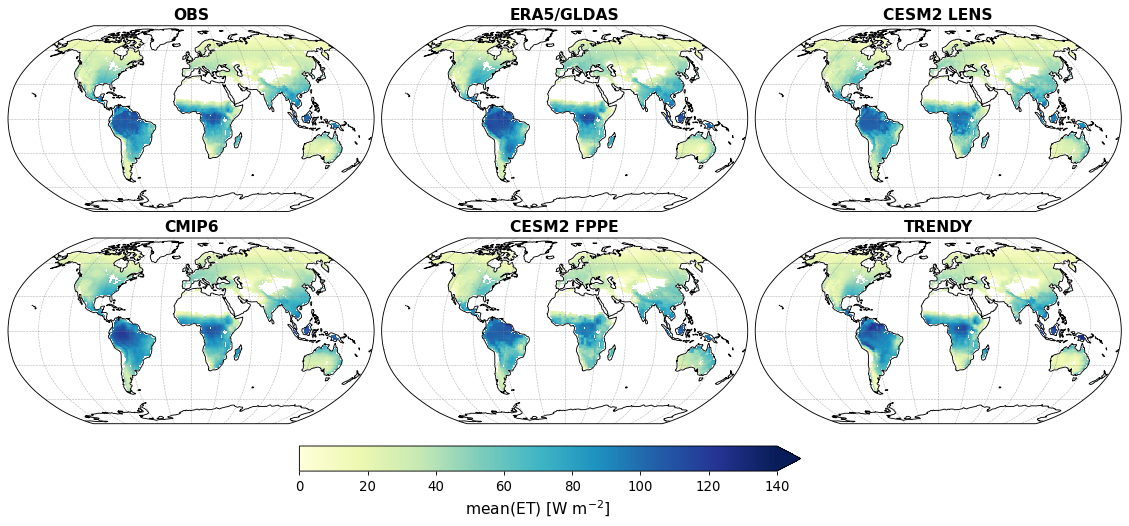

In [15]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    subplot_kw={"projection": ccrs.Robinson()},
    figsize=(14, 6.5),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()

for i, f in enumerate(FAMILIES_NO_IPPE):
    # da = variants.group_means(inputs[f].where(area).mean(dim="year"), f, "member").mean("group")[BIN_VARIABLE]
    # da = variants.group_means(inputs[f][BIN_VARIABLE].mean(dim="year"), f, "member").mean("group")
    da = inputs[f][BIN_VARIABLE].where(area).mean(dim="year").mean("member")
    mp = (
        da.plot(
            ax=axs[i],
            transform=ccrs.PlateCarree(),
            **plotting.MAP_KWARGS[BIN_VARIABLE],
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=140,
        )
    )
    plotting.map_ax(axs[i], slice(-90, 90))
    axs[i].set_global()
    axs[i].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.06,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("mean(ET) [W m$^{-2}$]", fontsize=14)

### 1.2. Maps of variance across each data family

#### Standard deviation

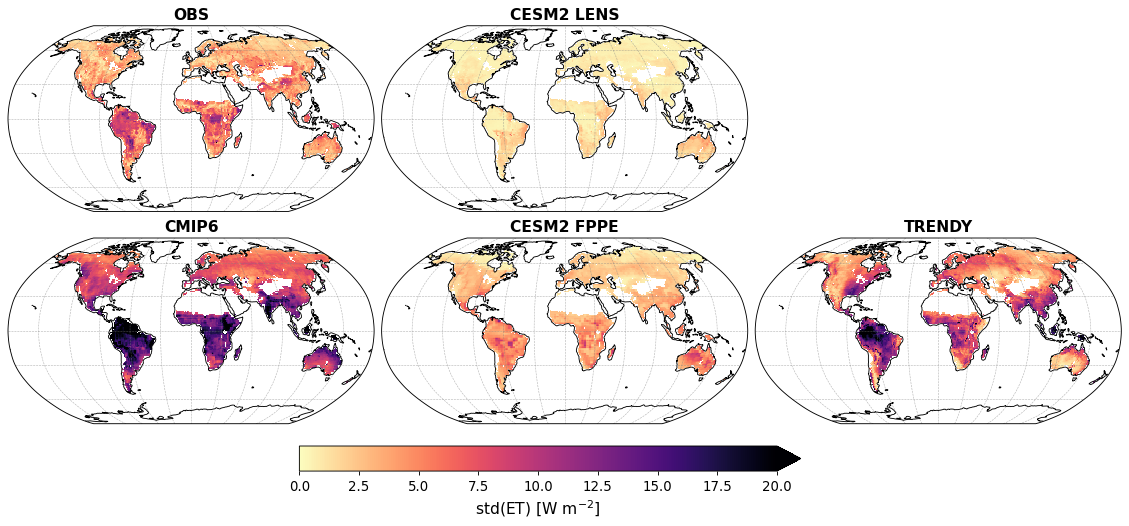

In [16]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    subplot_kw={"projection": ccrs.Robinson()},
    figsize=(14, 6.5),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]
panels = [0, 1, 3, 4, 5]

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = variants.group_means(inputs[f][BIN_VARIABLE].where(area).mean(dim="year"), f, "member").std("group")
    # da = variants.group_means(inputs[f][BIN_VARIABLE].mean(dim="year"), f, "member").std("group")
    da = inputs[f][BIN_VARIABLE].where(area).mean(dim="year").std("member")
    mp = (
        da.plot(
            ax=axs[j],
            transform=ccrs.PlateCarree(),
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=20,
        )
    )
    plotting.map_ax(axs[j], slice(-90, 90))
    axs[j].set_global()
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axes,
    location="bottom",
    fraction=0.06,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("std(ET) [W m$^{-2}$]", fontsize=14)

axs[2].remove()

#### Range

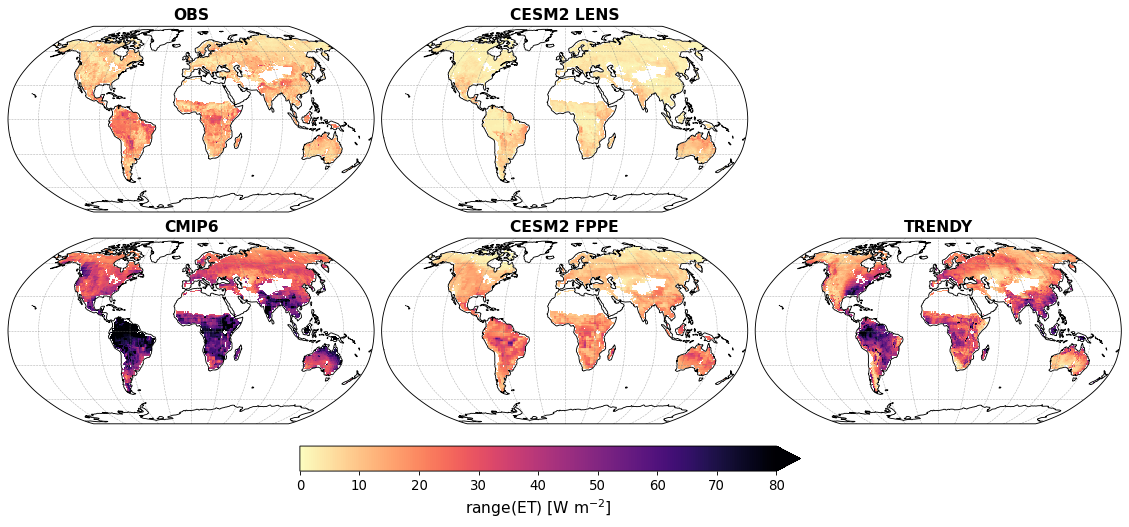

In [17]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    subplot_kw={"projection": ccrs.Robinson()},
    figsize=(14, 6.5),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]
panels = [0, 1, 3, 4, 5]

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = xrange(variants.group_means(inputs[f][BIN_VARIABLE].where(area).mean(dim="year"), f, "member"), dim="group")
    # da = xrange(inputs[f][BIN_VARIABLE].mean(dim="year"), dim="member")
    da = xrange(inputs[f][BIN_VARIABLE].where(area).mean(dim="year"), dim="member")
    mp = (
        da.plot(
            ax=axs[j],
            transform=ccrs.PlateCarree(),
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=80,
        )
    )
    plotting.map_ax(axs[j], slice(-90, 90))
    axs[j].set_global()
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.06,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("range(ET) [W m$^{-2}$]", fontsize=14)

axs[2].remove()

#### Percent range relative to mean

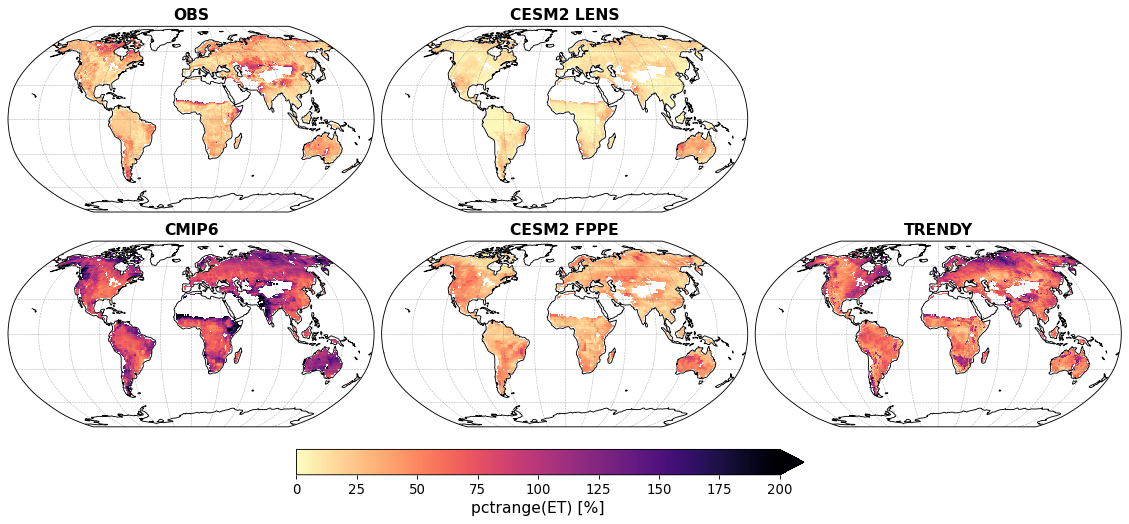

In [18]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    subplot_kw={"projection": ccrs.Robinson()},
    figsize=(14, 6.5),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]
panels = [0, 1, 3, 4, 5]

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = pctxrange(variants.group_means(inputs[f][BIN_VARIABLE].where(area).mean(dim="year"), f, "member"), dim="group")
    # da = pctxrange(inputs[f][BIN_VARIABLE].mean(dim="year"), dim="member")
    da = pctxrange(inputs[f][BIN_VARIABLE].where(area).mean(dim="year"), dim="member")
    mp = (
        da.plot(
            ax=axs[j],
            transform=ccrs.PlateCarree(),
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=200,
        )
    )
    plotting.map_ax(axs[j], slice(-90, 90))
    axs[j].set_global()
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.06,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("pctrange(ET) [%]", fontsize=14)

axs[2].remove()

### 1.3. Timeseries of domain-mean for each data family

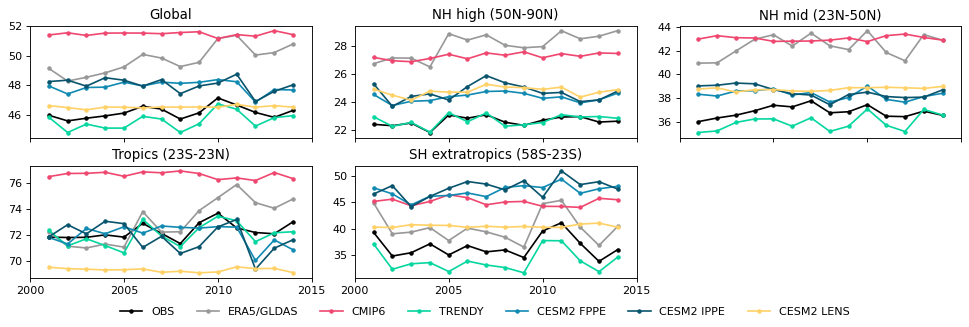

In [23]:
fig, axes = plt.subplots(
    nrows=2, ncols=3,
    figsize=(12, 4),
    layout="constrained",
    sharex=True,
    dpi=DPI,
)
axs = axes.ravel()

for i, (r, b) in enumerate(REGIONS.items()):
    w = la.sel(lat=b)
    for f in FAMILIES:
        da = inputs[f][BIN_VARIABLE].where(area).sel(lat=b)
        # mu = variants.group_means(da, f, "member").weighted(w).mean(dim=["lat", "lon"]).mean("group")
        mu = da.where(area).weighted(w).mean(dim=["lat", "lon"]).mean(dim="member")
        h = mu.plot(ax=axs[i], marker=".", label=FAMILY_KWARGS["labels"][f], color=FAMILY_KWARGS["colors"][f], _labels=False)

        # mn = variants.group_means(da, f, "member").weighted(w).mean(dim=["lat", "lon"]).min("group")
        # mx = variants.group_means(da, f, "member").weighted(w).mean(dim=["lat", "lon"]).max("group")
        # if (mn != mx).all():
        #     axs[i].fill_between(mu.year, mn, mx, alpha=0.1, color=FAMILY_KWARGS["colors"][f])
    
    axs[i].set_title(r)
    axs[i].set_xticks([2000, 2005, 2010, 2015])

axs[-1].remove()
# one legend for the figure: every panel has the same lines, so take them from the first
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=len(labels), frameon=False)

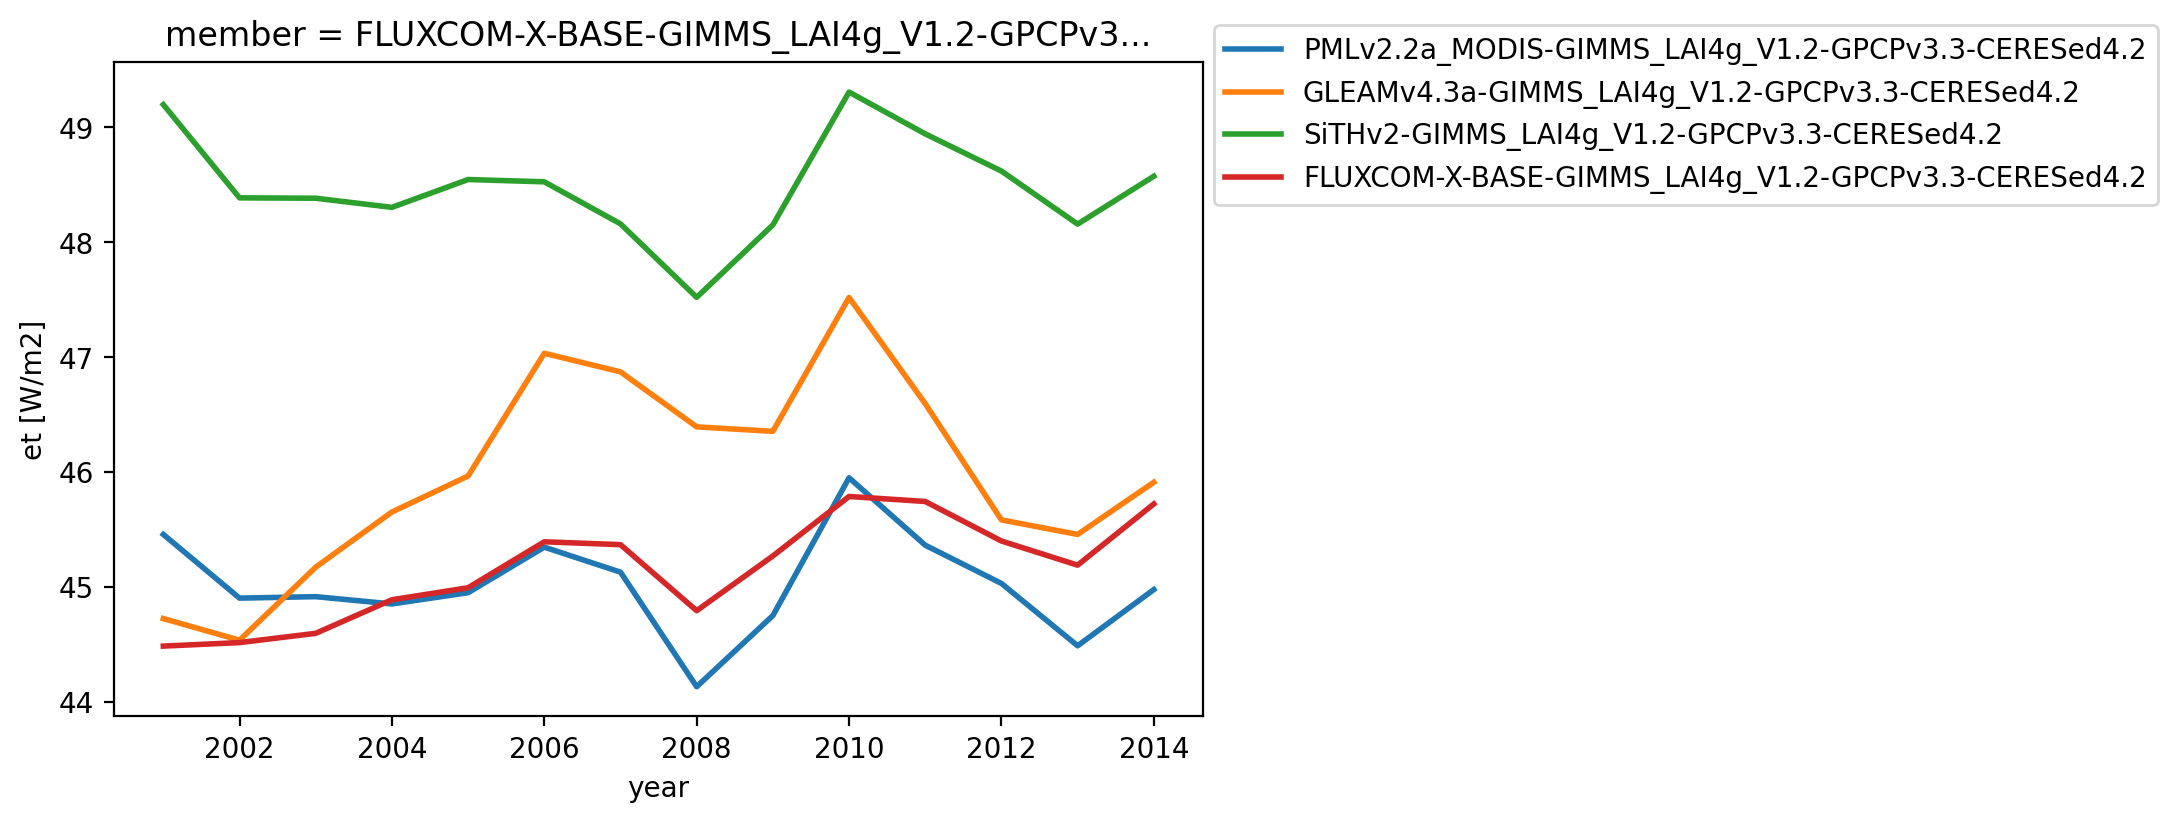

In [25]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained", dpi=200)
# da = variants.group_means(inputs["obs"][BIN_VARIABLE].where(area).weighted(la).mean(dim=["lat", "lon"]), "obs", "member")
da = inputs["obs"][BIN_VARIABLE].where(area).weighted(la).mean(dim=["lat", "lon"])
for m in da.member:
    da.sel(member=m).plot(lw=2, label=m.item())
fig.legend(bbox_to_anchor=(1.8, 1))

## 2. LAI-aridity binned mean ET

### 2.1. Mean across each data family

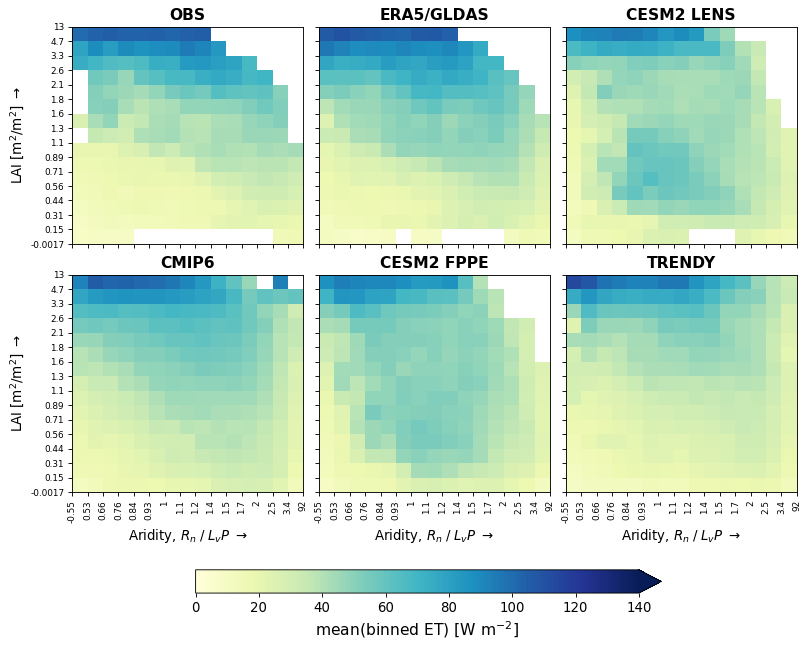

In [26]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()

for i, f in enumerate(FAMILIES_NO_IPPE):
    # Bin mean of each member, averaged within each group of variants, then across groups
    # da = variants.group_means(bin_mean[f], f, "member").mean("group")
    da = bin_mean[f].mean(dim="member")
    mp = (
        da.plot(
            ax=axs[i],
            x="x_bin",
            y="y_bin",
            **plotting.MAP_KWARGS[BIN_VARIABLE],
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=140,
        )
    )
    # Tick labels on the left column and on the lowest panel of each column
    bin_ax(axs[i], da, xlabels=i + axes.shape[1] >= len(FAMILIES_NO_IPPE), ylabels=i % axes.shape[1] == 0)
    axs[i].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("mean(binned ET) [W m$^{-2}$]", fontsize=14)

### 2.2. Variance across each data family

#### Standard deviation

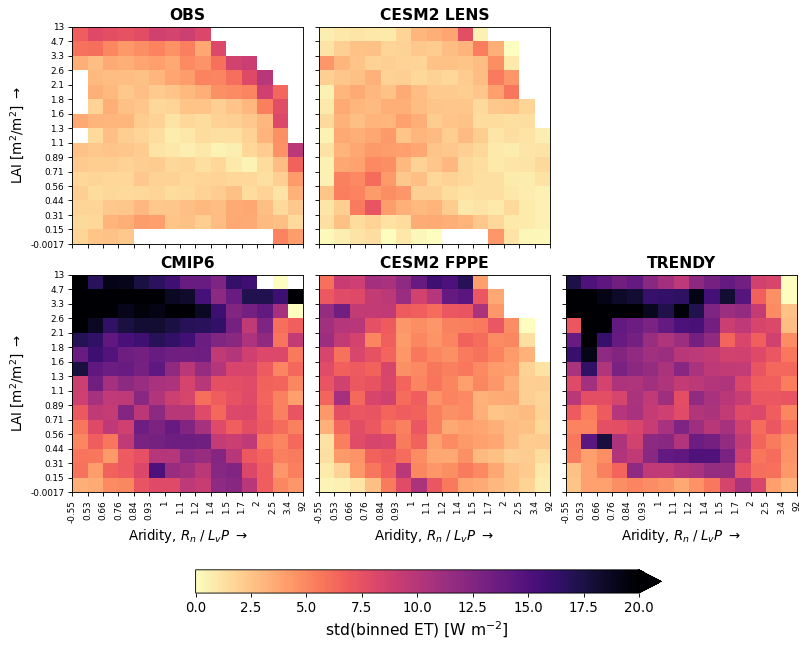

In [27]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]
panels = [0, 1, 3, 4, 5]

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = variants.group_means(bin_mean[f], f, "member").std("group")
    da = bin_mean[f].std(dim="member")
    mp = (
        da.plot(
            ax=axs[j],
            x="x_bin",
            y="y_bin",
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=20,
        )
    )
    bin_ax(axs[j], da, xlabels=j >= ncols, ylabels=j % ncols == 0)
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("std(binned ET) [W m$^{-2}$]", fontsize=14)

axs[2].remove()

#### Range

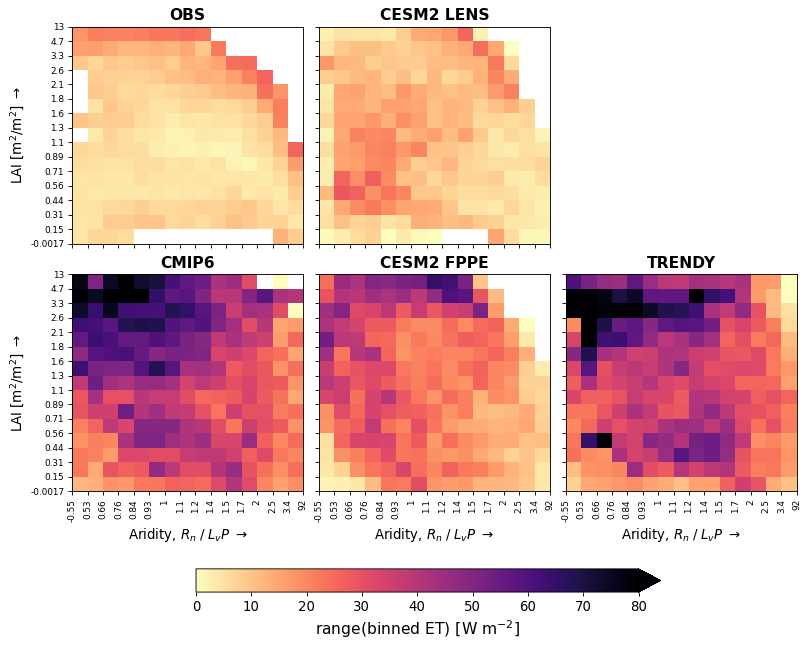

In [28]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]
panels = [0, 1, 3, 4, 5]

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = xrange(variants.group_means(bin_mean[f], f, "member"), dim="group")
    da = xrange(bin_mean[f], dim="member")
    mp = (
        da.plot(
            ax=axs[j],
            x="x_bin",
            y="y_bin",
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=80,
        )
    )
    bin_ax(axs[j], da, xlabels=j >= ncols, ylabels=j % ncols == 0)
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("range(binned ET) [W m$^{-2}$]", fontsize=14)

axs[2].remove()

#### Percent range relative to mean

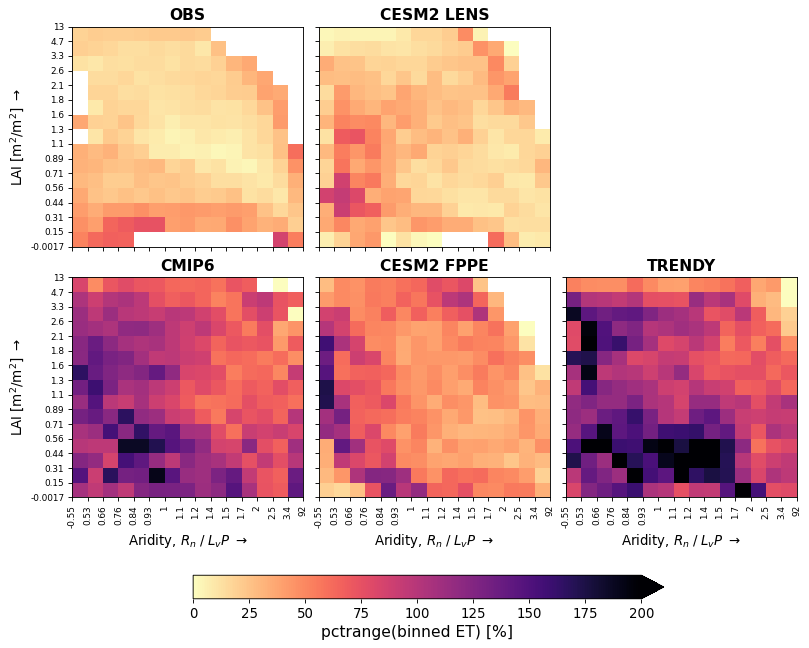

In [29]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()

for i, f in enumerate(FAMILIES_SHORT):
    j = panels[i]
    # da = pctxrange(variants.group_means(bin_mean[f], f, "member"), dim="group")
    da = pctxrange(bin_mean[f], dim="member")
    mp = (
        da.plot(
            ax=axs[j],
            x="x_bin",
            y="y_bin",
            cmap="magma_r",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=200,
        )
    )
    bin_ax(axs[j], da, xlabels=j >= ncols, ylabels=j % ncols == 0)
    axs[j].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("pctrange(binned ET) [%]", fontsize=14)

axs[2].remove()

## 3. LAI-aridity binned land fraction

### 3.1. Select 2-4 CMIP6 models and 2-4 FPPE members

In [32]:
LF_SELECTION = {
    "cmip": [
        "CESM2",
        "EC-Earth3-Veg",
        "GISS-E3-G",
        # "HadGEM3-GC31-MM",
        "UKESM1-0-LL",
    ],
    "fppe": [
        "9.medlynslope.min",
        "15.kmax.min",
        "21.leafcn.min",
        "26.KCN.max",
    ],
}

### 3.2. Land fraction total for select models

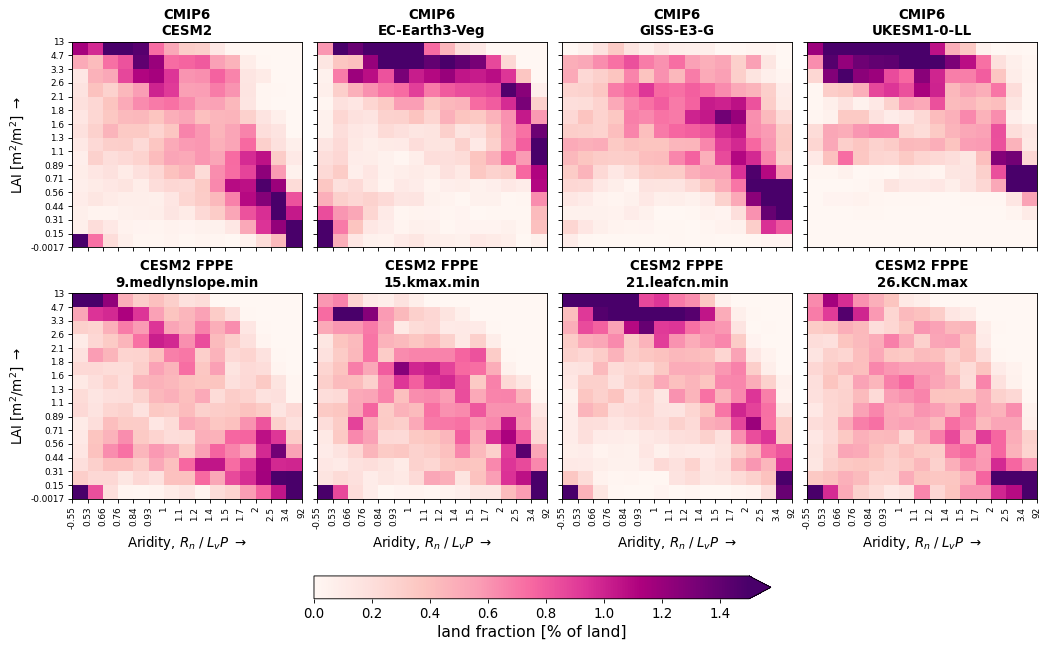

In [33]:
fig, axes = plt.subplots(
    nrows=len(LF_SELECTION),
    ncols=max(len(s) for s in LF_SELECTION.values()),
    figsize=(13, 8),
    layout="constrained",
    dpi=DPI,
)

for r, (f, sources) in enumerate(LF_SELECTION.items()):
    # Land fraction of each source (its members averaged)
    lf = land_frac[f].groupby("source").mean()
    for c, s in enumerate(sources):
        da = lf.sel(source=s)
        mp = (
            da.plot(
                ax=axes[r, c],
                x="x_bin",
                y="y_bin",
                cmap="RdPu",
                add_colorbar=False,
                add_labels=False,
                vmin=0, vmax=1.5,
            )
        )
        bin_ax(axes[r, c], da, xlabels=r == axes.shape[0] - 1, ylabels=c == 0)
        axes[r, c].set_title(f"{FAMILY_KWARGS['labels'][f]}\n{s}", fontsize=12, fontweight="bold")
    # Unused panels of a row with fewer sources
    for c in range(len(sources), axes.shape[1]):
        axes[r, c].remove()

cb = fig.colorbar(
    mp,
    ax=axes,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("land fraction [% of land]", fontsize=14)

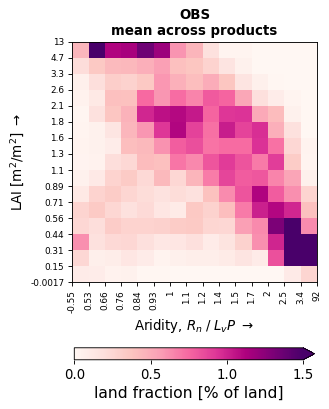

In [34]:
# OBS reference: land fraction averaged within each group of variants, then across groups
fig, ax = plt.subplots(
    figsize=(4, 5),
    layout="constrained",
    dpi=DPI,
)

# da = variants.group_means(land_frac["obs"], "obs", "member").mean("group")
da = land_frac["obs"].mean("member")
mp = (
    da.plot(
        ax=ax,
        x="x_bin",
        y="y_bin",
        cmap="RdPu",
        add_colorbar=False,
        add_labels=False,
        vmin=0, vmax=1.5,
    )
)
bin_ax(ax, da)
ax.set_title(f"{FAMILY_KWARGS['labels']['obs']}\nmean across products", fontsize=12, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=ax,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("land fraction [% of land]", fontsize=14)

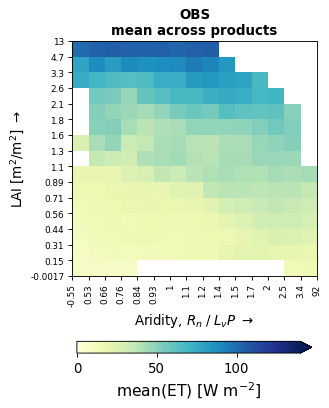

In [35]:
fig, ax = plt.subplots(
    figsize=(4, 5),
    layout="constrained",
    dpi=DPI,
)

# da = variants.group_means(bin_mean["obs"], "obs", "member").mean("group")
da =bin_mean["obs"].mean(dim="member")
mp = (
    da.plot(
        ax=ax,
        x="x_bin",
        y="y_bin",
        **plotting.MAP_KWARGS[BIN_VARIABLE],
        add_colorbar=False,
        add_labels=False,
        vmin=0, vmax=140,
    )
)
bin_ax(ax, da)
ax.set_title(f"{FAMILY_KWARGS['labels']['obs']}\nmean across products", fontsize=12, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=ax,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("mean(ET) [W m$^{-2}$]", fontsize=14)

### 3.3. Land fraction variance across each data family

#### Standard deviation

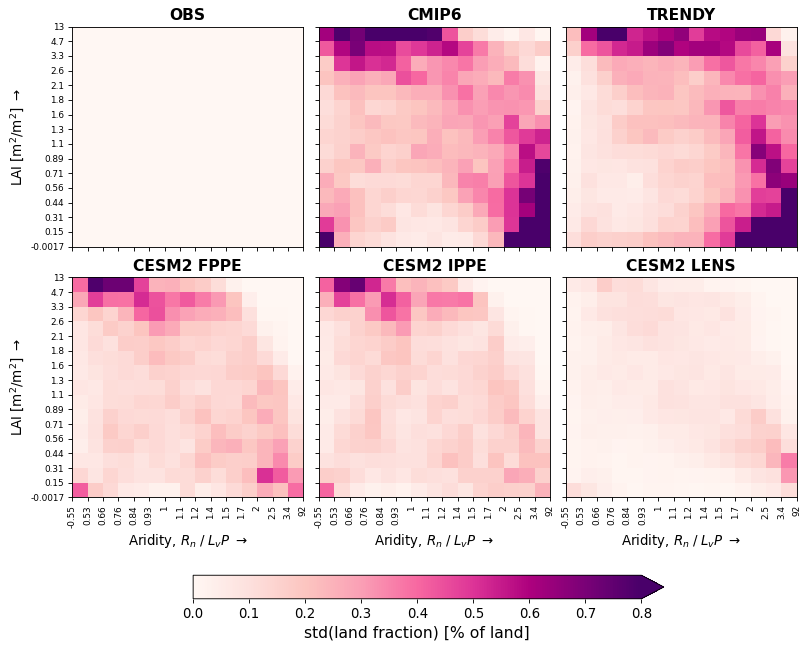

In [45]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()

for i, f in enumerate(FAMILIES_NO_ERA5):
    # Not masked by MIN_BIN_COUNT: a small land fraction is the value itself, not a noisy estimate
    # da = variants.group_means(land_frac[f], f, "member").std("group")
    da = land_frac[f].std("member")
    mp = (
        da.plot(
            ax=axs[i],
            x="x_bin",
            y="y_bin",
            cmap="RdPu",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=0.8,
        )
    )
    bin_ax(axs[i], da, xlabels=i + axes.shape[1] >= len(FAMILIES_NO_ERA5), ylabels=i % axes.shape[1] == 0)
    axs[i].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("std(land fraction) [% of land]", fontsize=14)

#### Range

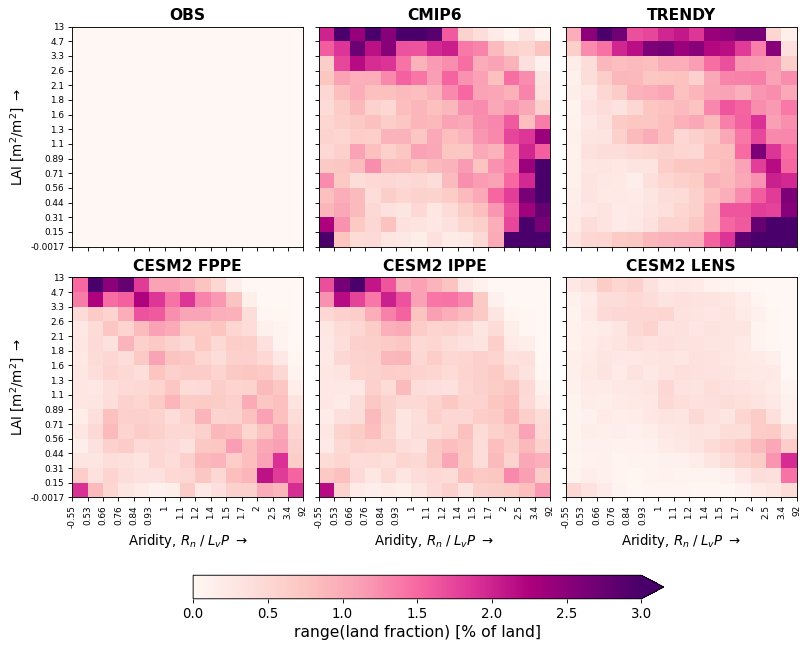

In [37]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 8),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()

for i, f in enumerate(FAMILIES_NO_ERA5):
    # da = xrange(variants.group_means(land_frac[f], f, "member"), dim="group")
    da = xrange(land_frac[f], dim="member")
    mp = (
        da.plot(
            ax=axs[i],
            x="x_bin",
            y="y_bin",
            cmap="RdPu",
            add_colorbar=False,
            add_labels=False,
            vmin=0, vmax=3,
        )
    )
    bin_ax(axs[i], da, xlabels=i + axes.shape[1] >= len(FAMILIES_NO_ERA5), ylabels=i % axes.shape[1] == 0)
    axs[i].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.05,
    pad=0.05,
    extend="max",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("range(land fraction) [% of land]", fontsize=14)

## 4. State-function decomposition relative to `obs` using the LAI-aridity bins

### 4.1. Box plot of the terms for each data family
`E_mm`, `E_mr`, `E_rm`

One box per family and counterfactual mean (`E_mm`, `E_rm`, `E_mr`), across the family's members, each against `obs_pooled` (the `<family>_pooled` rows are left out). The obs box is `E_rr` of each obs source against itself: with a complete support this is the source's full-domain ET, so the box is the spread across the ET products. The dashed line is the ET of `obs_pooled`, the reference of every family's boxes. Whiskers: 1.5 IQR; a family with one member (ERA5) is drawn as a marker.

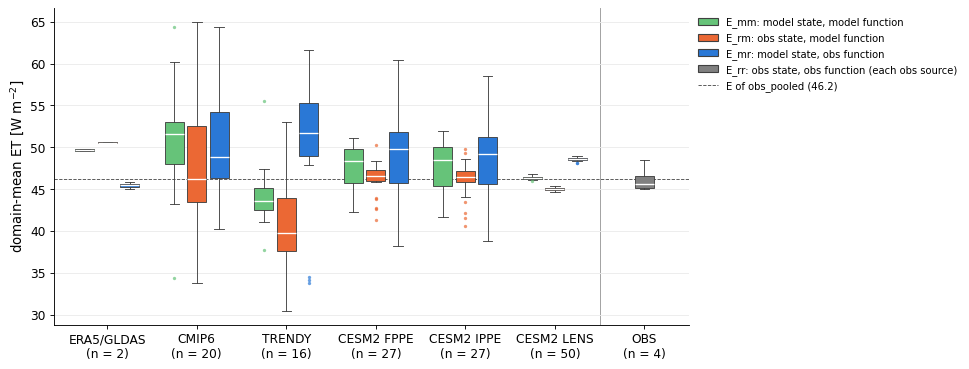

In [38]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

DECOMP_FAMILIES = [f for f in FAMILIES if f != "obs"]
MEANS = ["E_mm", "E_rm", "E_mr"]
DECOMP_COLORS = {"E_rr": "#808080", "E_rm": "#eb6834", "E_mr": "#2a78d6", "E_mm": "#66c379"}
DECOMP_LABELS = {
    "E_mm": "E_mm: model state, model function",
    "E_rm": "E_rm: obs state, model function",
    "E_mr": "E_mr: model state, obs function",
    "E_rr": "E_rr: obs state, obs function (each obs source)",
}

# Members of every family against obs_pooled, without the <family>_pooled rows
ref = vs_obs.sel(obs_reference="obs_pooled")
members = ref.isel(dataset=np.flatnonzero((ref["source"] != "pooled").values))

# Obs: E_rr of each obs source against itself (its own reference)
obs_idx = np.flatnonzero((vs_obs["family"] == "obs").values)
obs_self = np.array([float(vs_obs["E_rr"].isel(dataset=i).sel(obs_reference=str(vs_obs["source"].values[i])))
                     for i in obs_idx])


def draw_box(ax, values, x, color, width):
    """A box and whiskers of `values` at `x`; a single value as a marker."""
    if values.size == 1:
        ax.scatter([x], values, marker="D", s=30, color=color, edgecolor="0.25", linewidth=0.6, zorder=3)
        return
    ax.boxplot(values, positions=[x], widths=width, patch_artist=True, zorder=2,
               boxprops=dict(facecolor=color, edgecolor="0.25", linewidth=0.8),
               medianprops=dict(color="white", linewidth=1.2),
               whiskerprops=dict(color="0.25", linewidth=0.8), capprops=dict(color="0.25", linewidth=0.8),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=color, markeredgecolor="none", alpha=0.7))


width = 0.25
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained", dpi=DPI)
ticks, ticklabels = [], []
for i, f in enumerate(DECOMP_FAMILIES):
    sel = members.isel(dataset=np.flatnonzero((members["family"] == f).values))
    for k, q in enumerate(MEANS):
        draw_box(ax, sel[q].values, i + (k - 1) * width, DECOMP_COLORS[q], 0.85 * width)
    ticks.append(i)
    ticklabels.append(f"{FAMILY_KWARGS['labels'][f]}\n(n = {sel.sizes['dataset']})")

# Obs, set apart by a line
x_obs = len(DECOMP_FAMILIES)
ax.axvline(x_obs - 0.5, color="0.6", linewidth=0.8, zorder=1)
draw_box(ax, obs_self, x_obs, DECOMP_COLORS["E_rr"], 0.85 * width)
ticks.append(x_obs)
ticklabels.append(f"{FAMILY_KWARGS['labels']['obs']}\n(n = {obs_self.size})")

# The reference of every family's boxes
E_pool = float(ref["E_r"].isel(dataset=0))
ax.axhline(E_pool, color="0.3", linestyle="--", linewidth=0.8, zorder=1)

ax.set_xticks(ticks, ticklabels, fontsize=11)
ax.set_xlim(-0.6, x_obs + 0.5)
ax.tick_params(axis="y", labelsize=11)
ax.set_ylabel("domain-mean ET [W m$^{-2}$]", fontsize=12)
ax.grid(axis="y", color="0.92", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
handles = [Patch(facecolor=DECOMP_COLORS[q], edgecolor="0.25", label=DECOMP_LABELS[q]) for q in MEANS + ["E_rr"]]
handles.append(Line2D([], [], color="0.3", linestyle="--", linewidth=0.8, label=f"E of obs_pooled ({E_pool:.1f})"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9, frameon=False)

## S1. Panel plots for all models/members for each data family

### S1.1. LAI-aridity binned mean ET

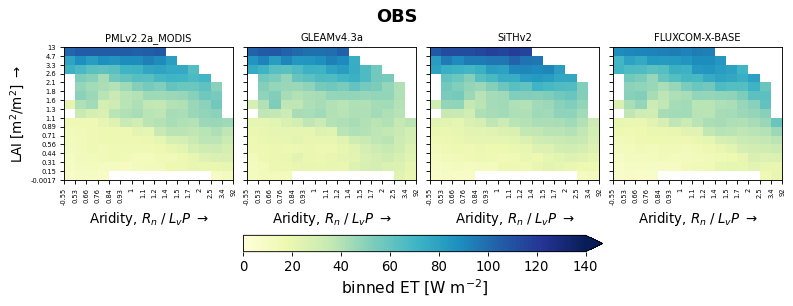

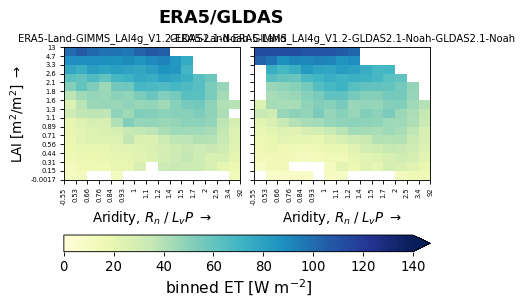

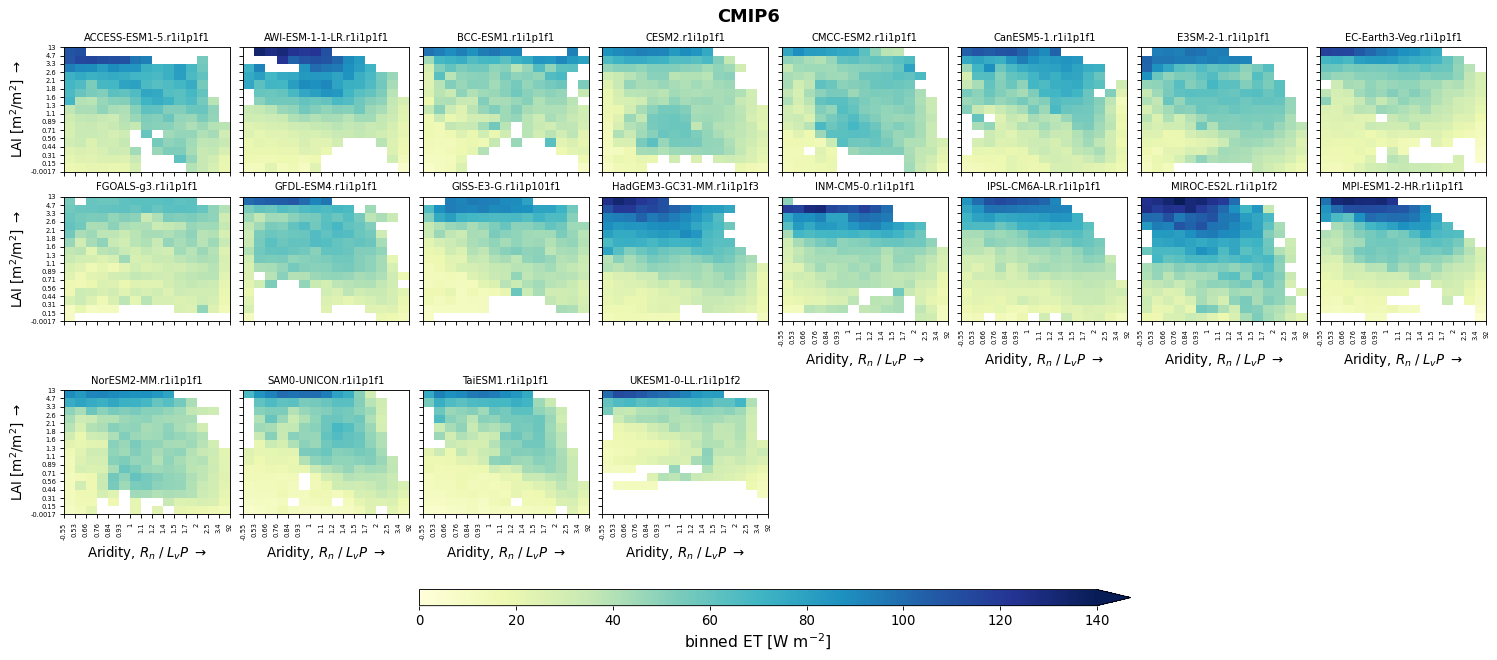

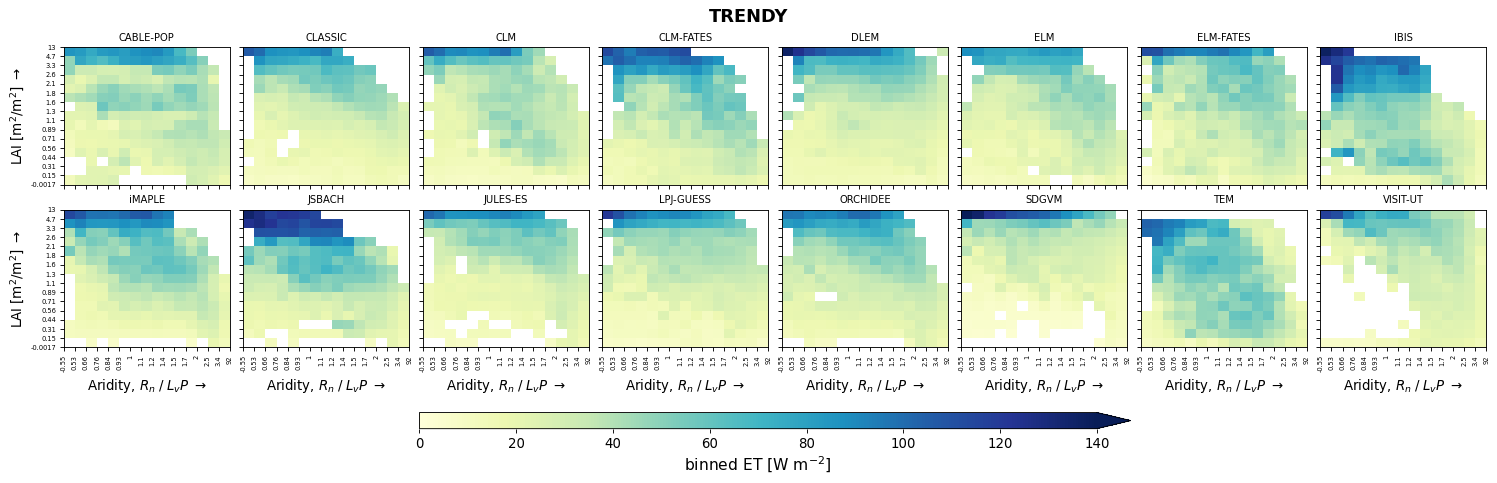

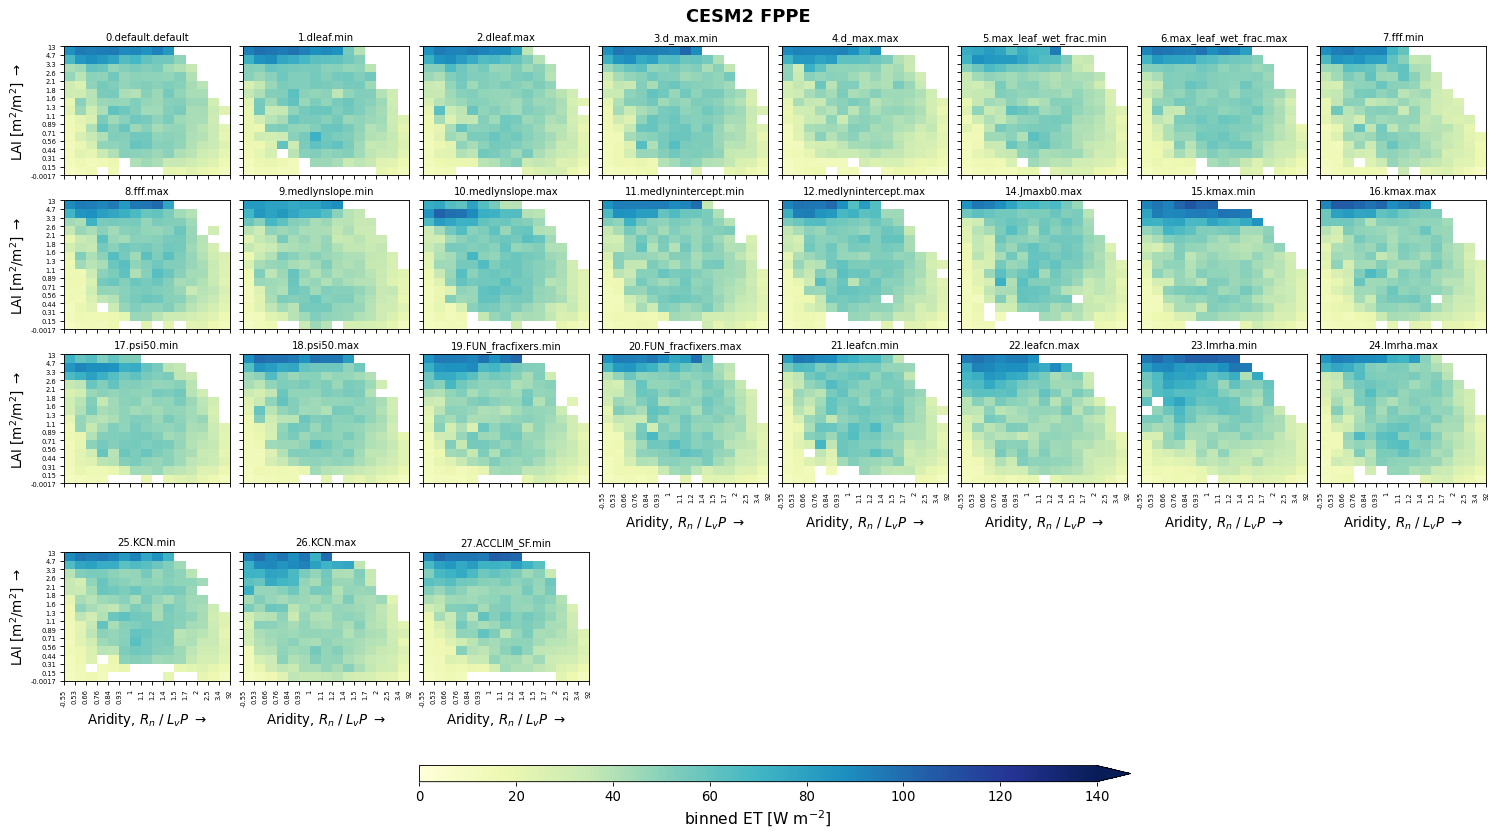

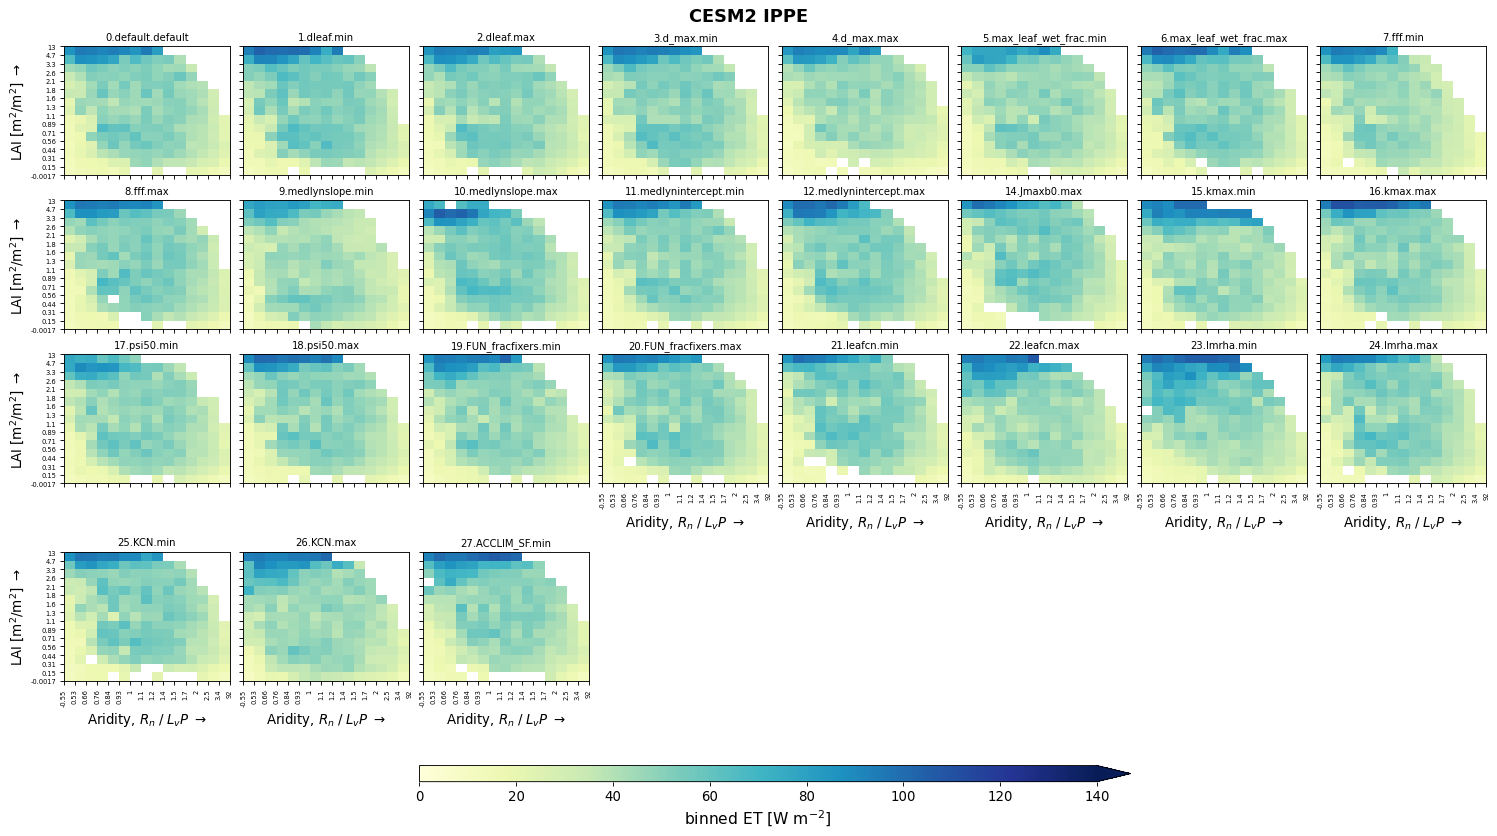

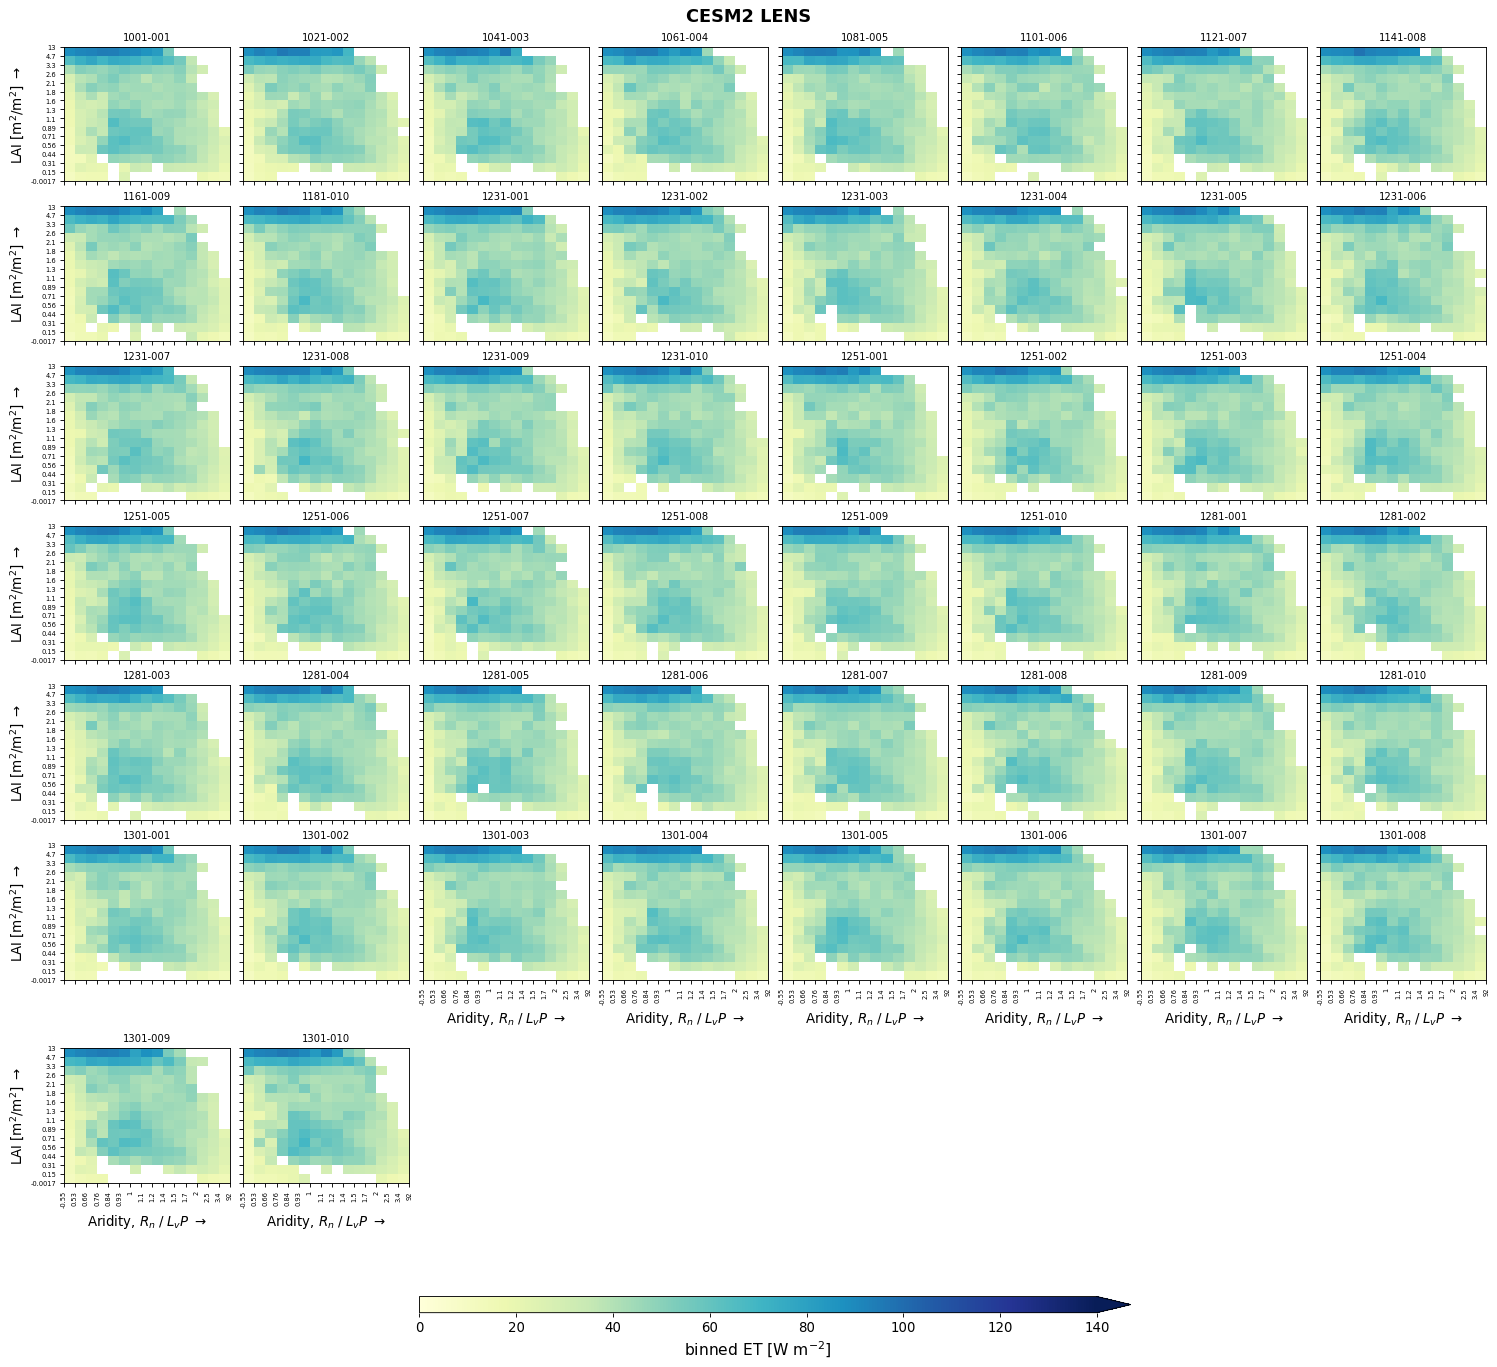

In [40]:
# Each member's bin means, masked by MIN_BIN_COUNT as in 2.1
for f in FAMILIES:
    member_panels(bin_mean[f], f, "binned ET [W m$^{-2}$]", **plotting.MAP_KWARGS[BIN_VARIABLE], vmin=0, vmax=140)
    plt.show()

### S1.2. LAI-aridity binned land fraction

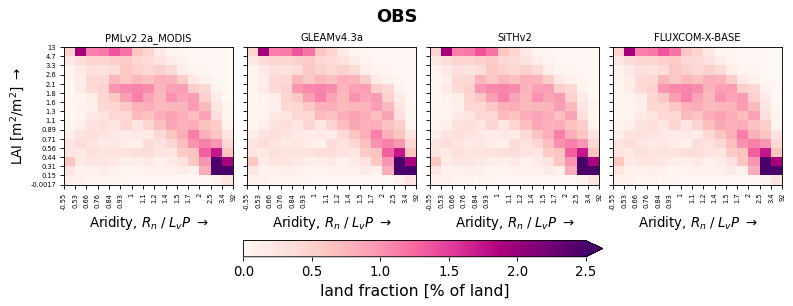

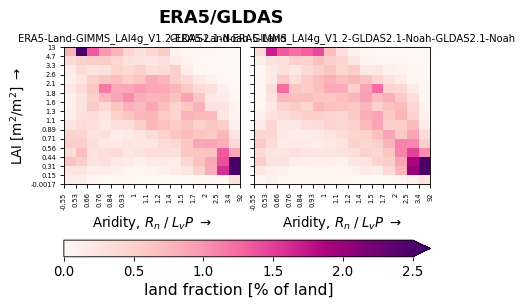

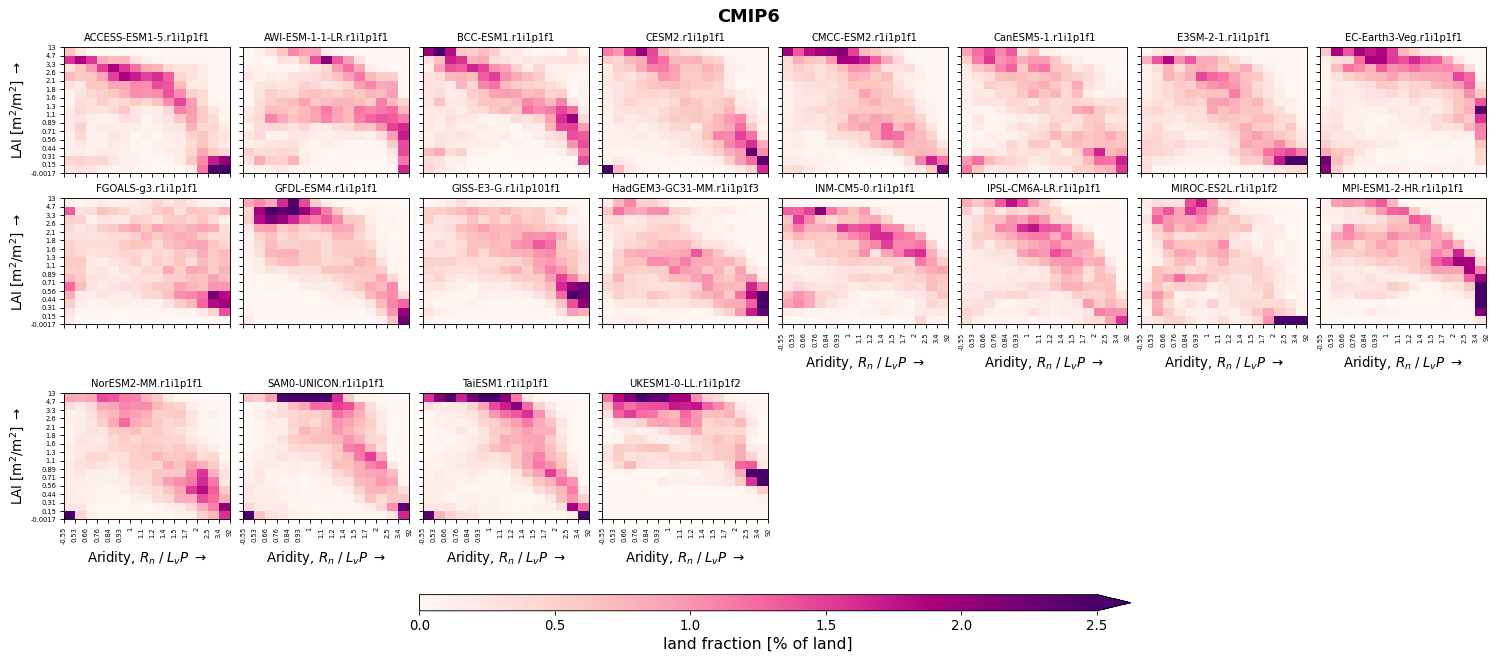

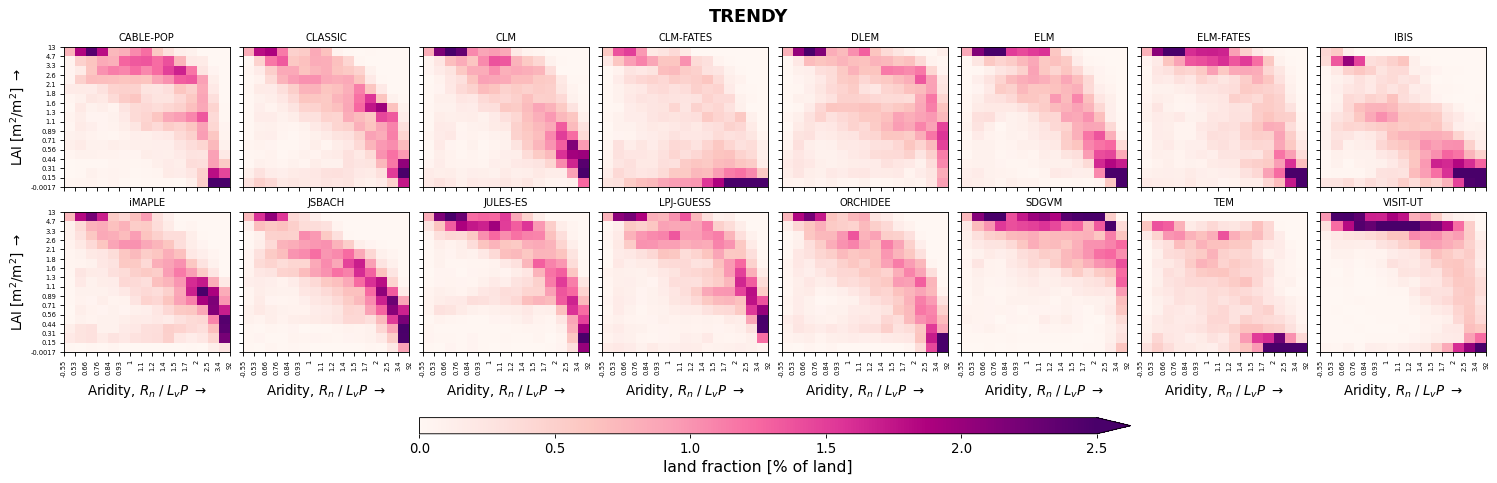

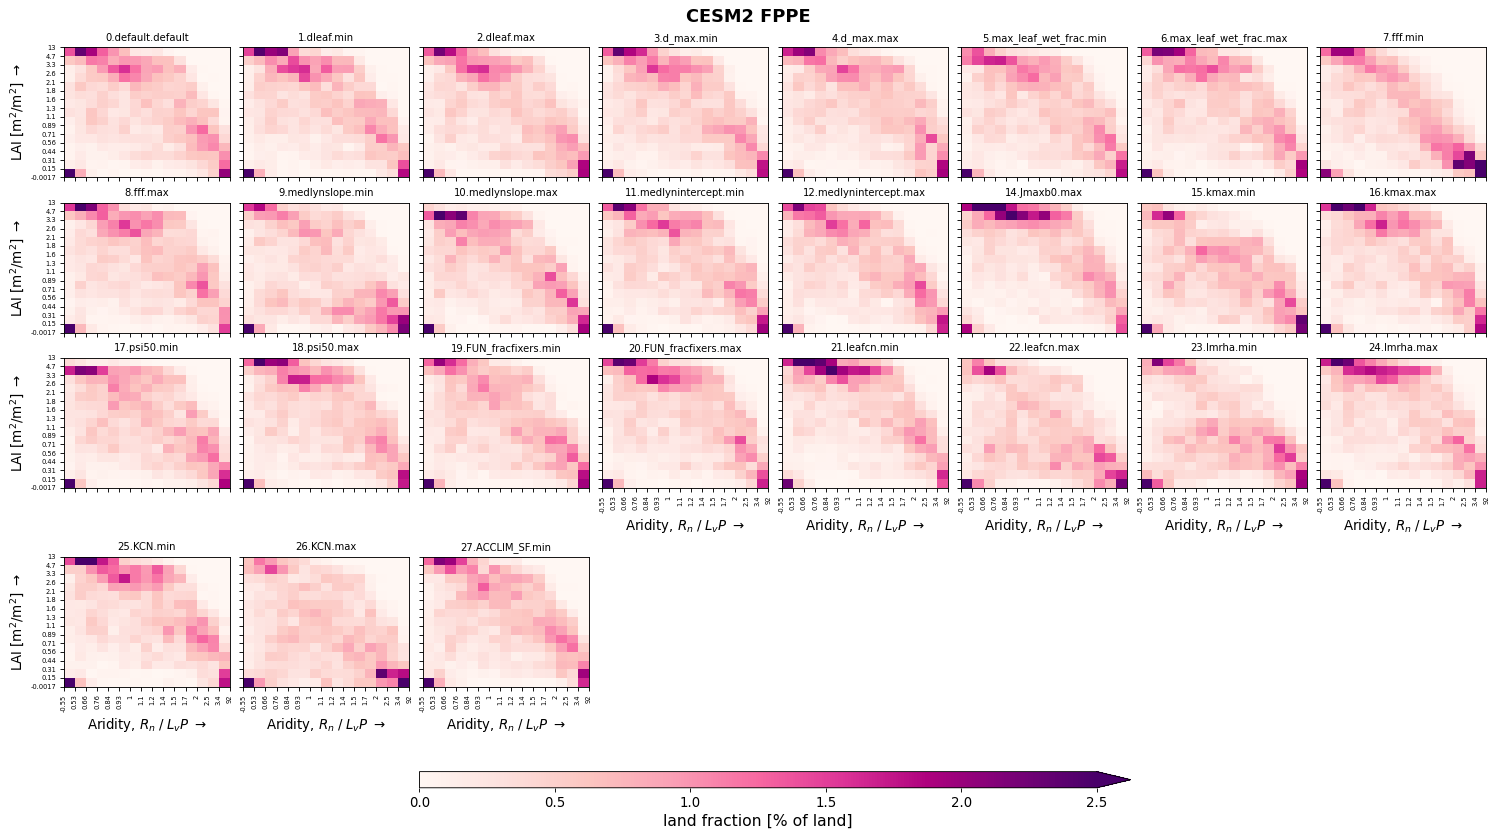

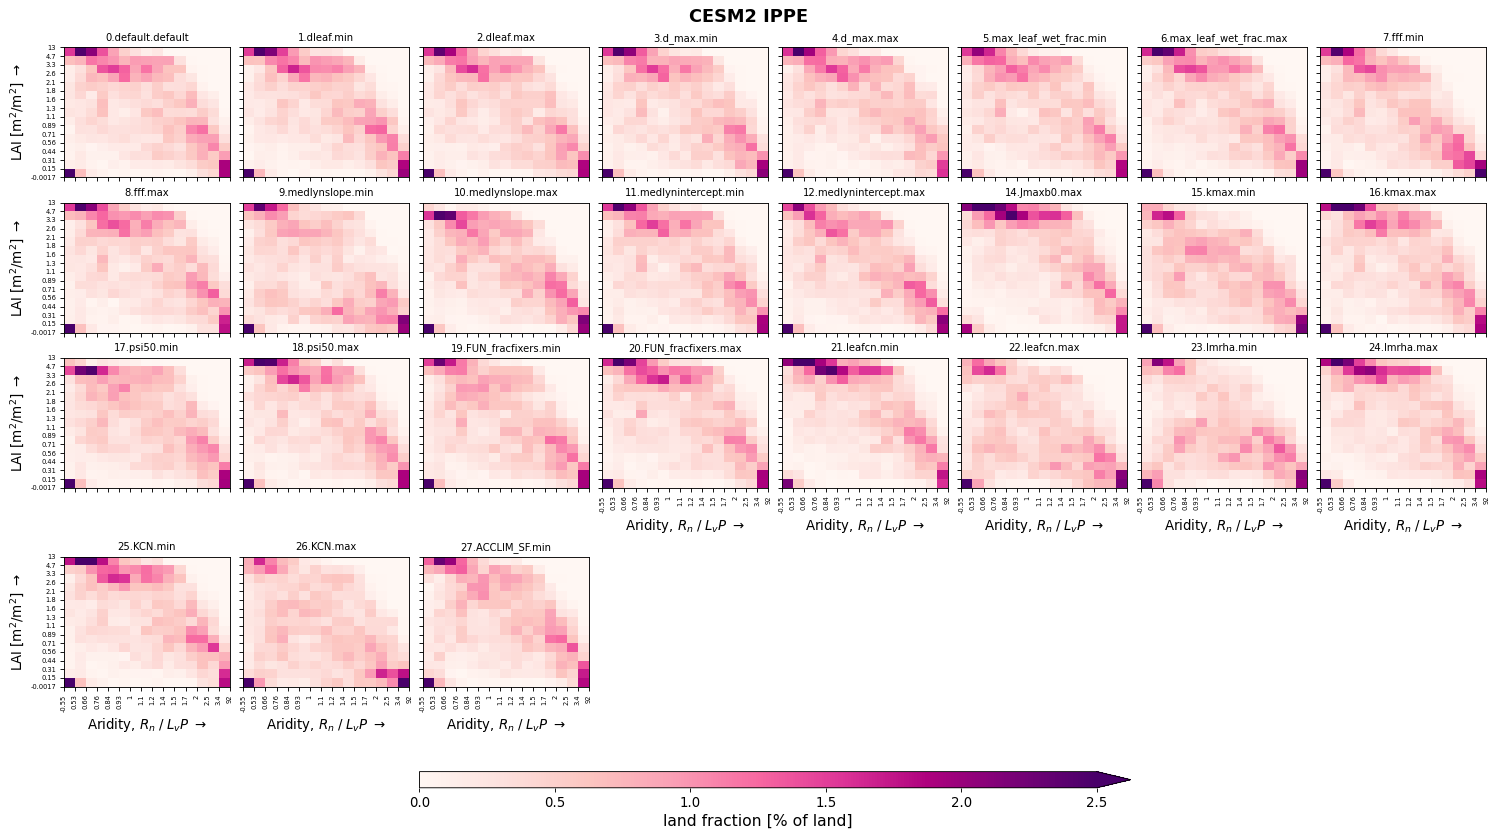

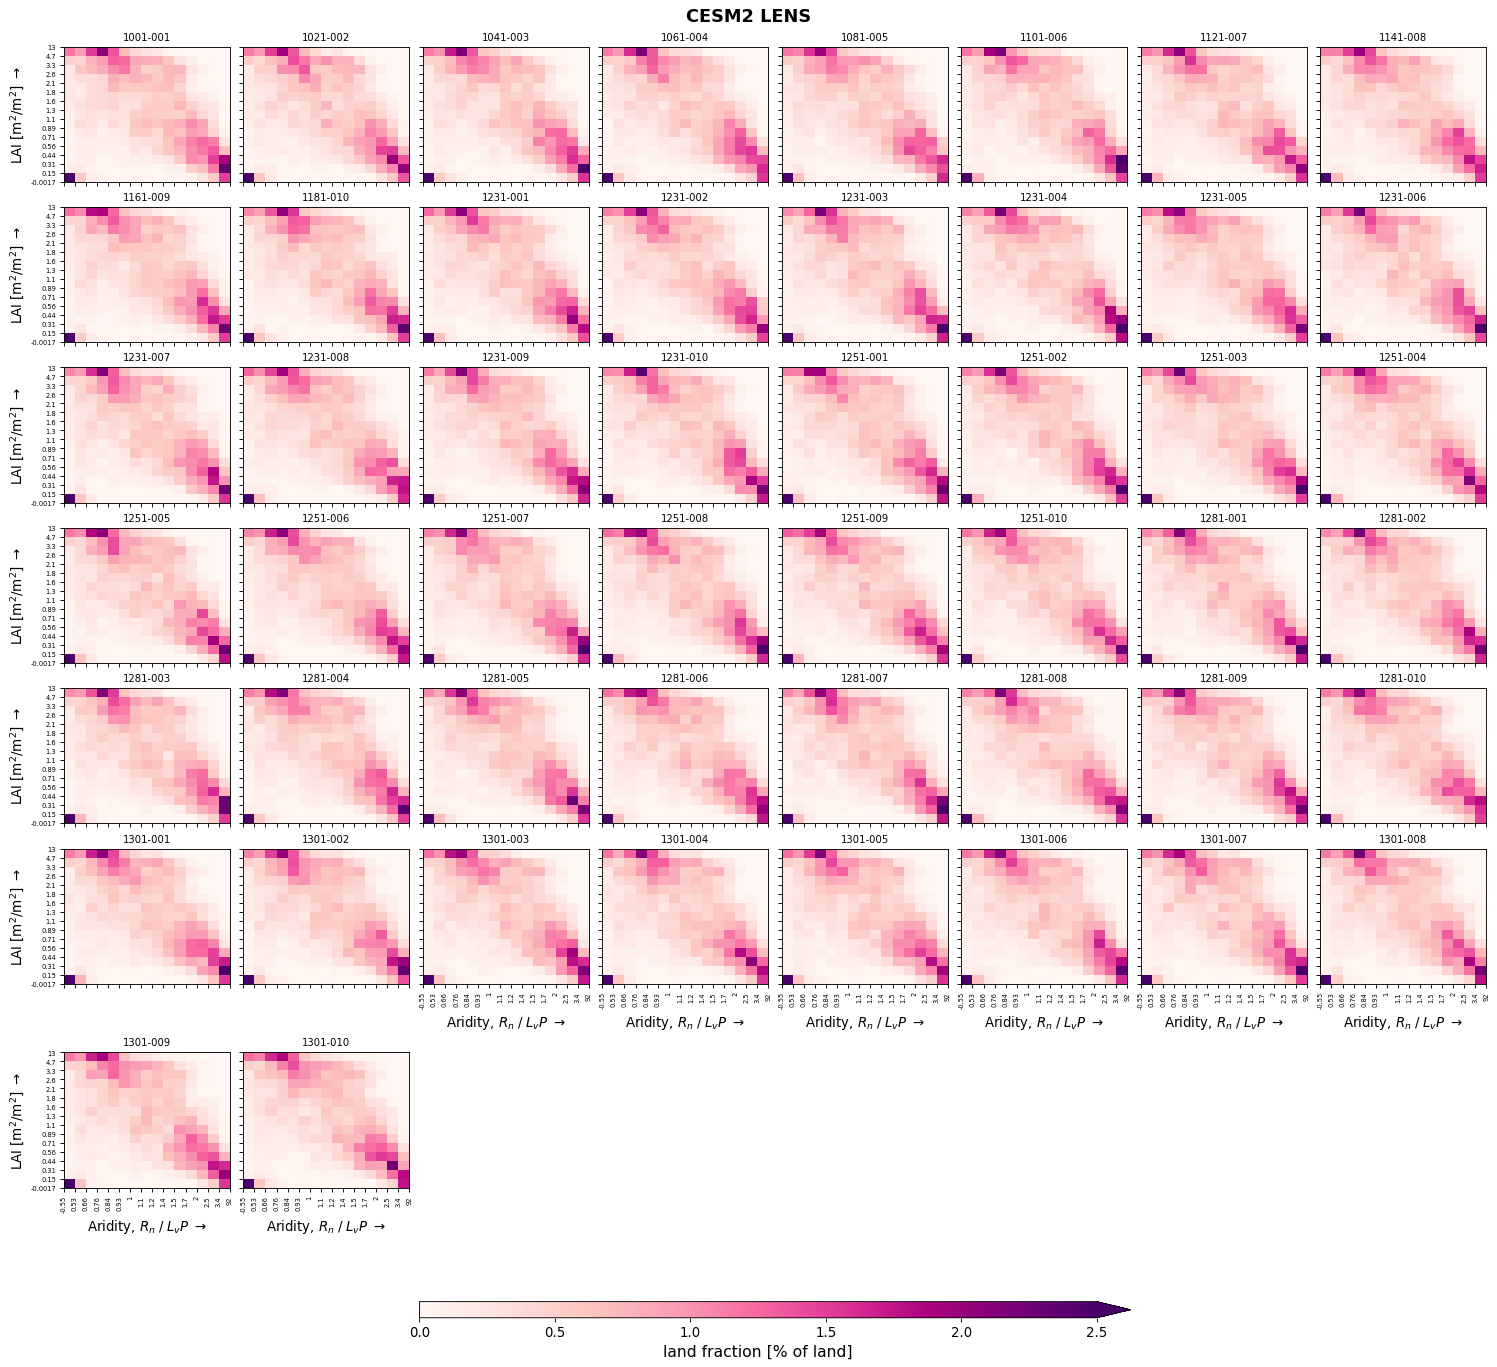

In [41]:
# Each member's land fraction, not masked (as in 3.2)
for f in FAMILIES:
    member_panels(land_frac[f], f, "land fraction [% of land]", cmap="RdPu", vmin=0, vmax=2.5)
    plt.show()

### S1.3. State-function decomposition
Each member against `obs_pooled` (the decomposition of 4.1): the terms STATE = `E_mr - E_rr`, FUNCTION = `E_rm - E_rr` and INTERACTION, which sum to `E_mm - E_rr` (black diamonds), with the members sorted by `E_mm - E_rr` (most negative to most positive). Needs the 4.1 cell to be run first.

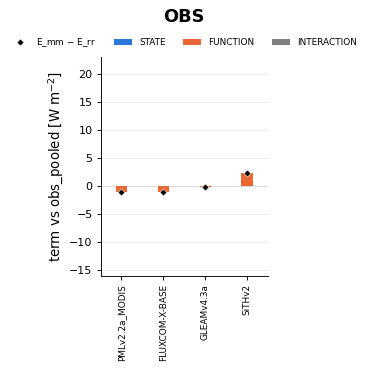

/glade/u/home/bbuchovecky/projects/et_unc/.pixi/envs/default/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


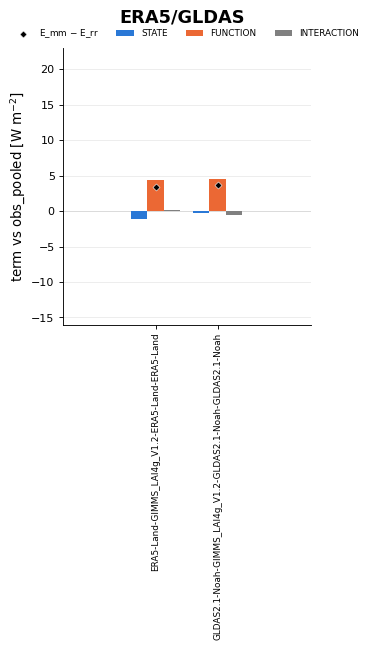

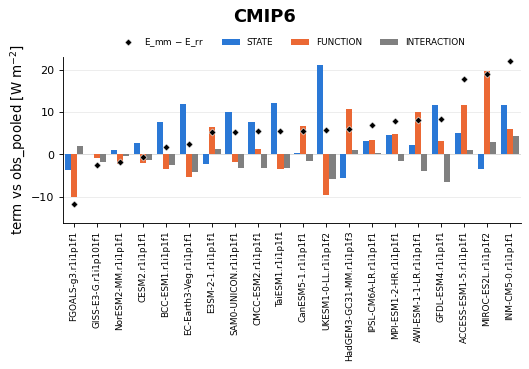

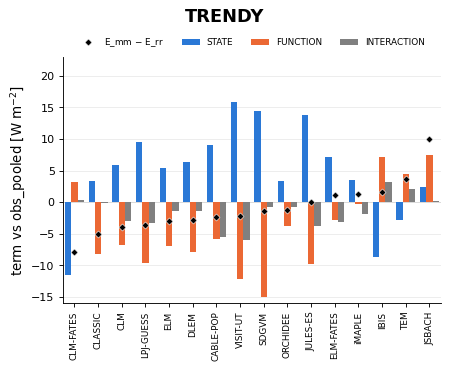

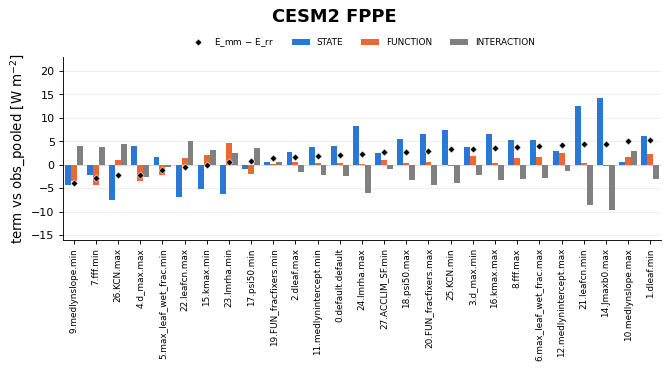

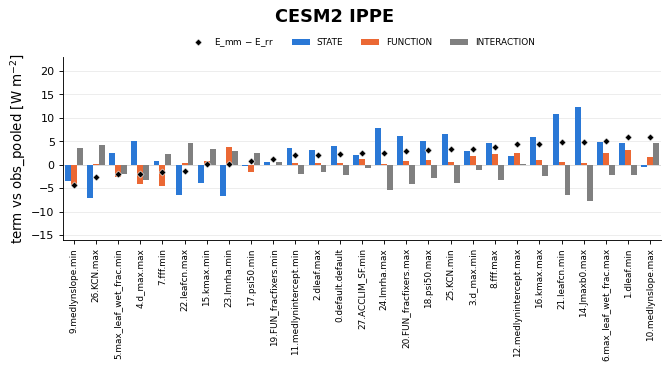

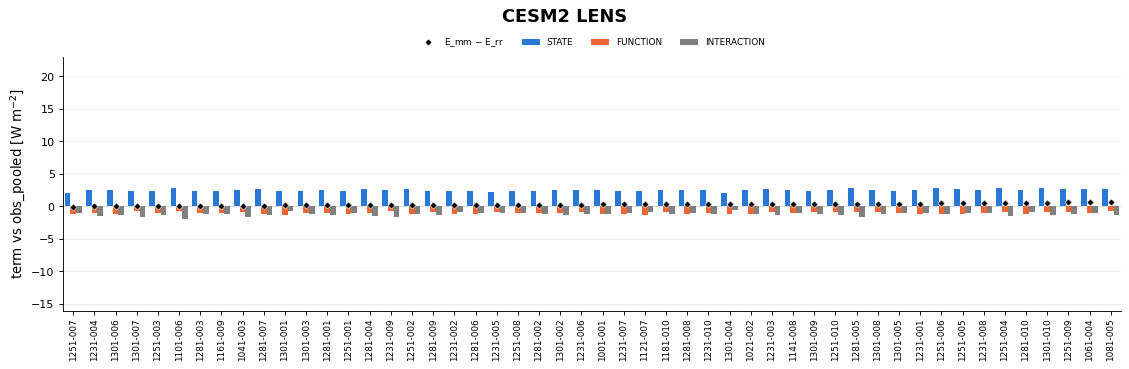

In [42]:
# Each member against obs_pooled: the decomposition of E_mm - E_rr into the state, function and interaction
# terms (bars) and their sum E_mm - E_rr (marker), members sorted by E_mm - E_rr
TERMS = ["STATE", "FUNCTION", "INTERACTION"]
# STATE = E_mr - E_rr and FUNCTION = E_rm - E_rr, so each term takes the color of its counterfactual mean
TERM_COLORS = {"STATE": DECOMP_COLORS["E_mr"], "FUNCTION": DECOMP_COLORS["E_rm"], "INTERACTION": "#808080"}

# Shared y-limits across families, covering the terms and their sum
TOTAL = members["E_mm"] - members["E_rr"]
term_lim = (min(float(min(members[t].min() for t in TERMS)), float(TOTAL.min())) - 1,
            max(float(max(members[t].max() for t in TERMS)), float(TOTAL.max())) + 1)

for f in FAMILIES:
    sel = members.isel(dataset=np.flatnonzero((members["family"] == f).values))
    sel = sel.isel(dataset=np.argsort((sel["E_mm"] - sel["E_rr"]).values))  # most negative to most positive
    n = sel.sizes["dataset"]
    labels = sel["et_product"].values if f == "obs" else sel["source"].values if f == "trendy_s3" else \
        [str(d).split(".", 1)[1] for d in sel["dataset"].values]
    x = np.arange(n)

    fig, ax = plt.subplots(
        figsize=(max(0.25 * n + 1.5, 4), 4.5),
        layout="constrained",
        dpi=DPI,
    )
    # Grouped vertical bars, one per term
    w = 0.8 / len(TERMS)
    for k, t in enumerate(TERMS):
        ax.bar(x + (k - 1) * w, sel[t].values, width=w, color=TERM_COLORS[t], label=t, zorder=2)
    # The sum of the terms, at the center of each member's bars
    ax.scatter(x, sel["E_mm"].values - sel["E_rr"].values, marker="D", s=20, color="k", edgecolor="w",
               linewidth=0.5, label="E_mm $-$ E_rr", zorder=3)
    ax.axhline(0, color="0.3", linewidth=0.8, zorder=1)
    ax.set_ylim(term_lim)
    ax.set_ylabel("term vs obs_pooled [W m$^{-2}$]", fontsize=12)

    ax.set_xticks(x, labels, fontsize=8, rotation=90)
    # At least 4 member slots wide, centered on the members, so a family of 1-3 members keeps narrow bars
    half = max(n, 4) / 2
    ax.set_xlim((n - 1) / 2 - half, (n - 1) / 2 + half)
    ax.grid(axis="y", color="0.92", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=4, fontsize=8, frameon=False)
    fig.suptitle(FAMILY_KWARGS["labels"][f], fontsize=16, fontweight="bold")
    plt.show()

### S1.4. State shift
Each member against `obs_pooled` (comparison 5 of `scripts/decompose_state_function.py`): the land in other bins than `obs_pooled`, LAND_SHIFT = sum_b |p_m - p_r| / 2 (top), and STATE split into the bins the member gains land in (STATE_GAINS = sum_S max(dp, 0) f_r) and loses land from (STATE_LOSSES = sum_S min(dp, 0) f_r), with STATE their sum (bottom). Members ordered by LAND_SHIFT (largest first), the pooled family last. Since sum_b dp = 0, a large LAND_SHIFT gives a small STATE when the land moves between bins of similar observed ET.

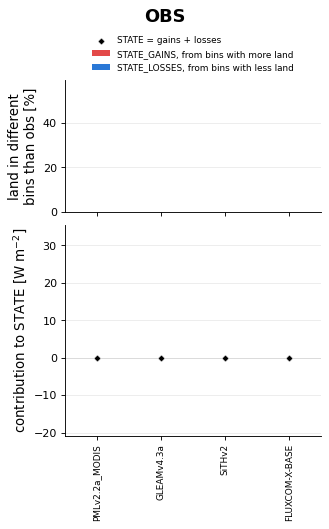

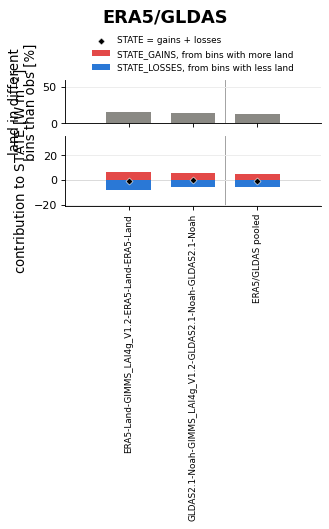

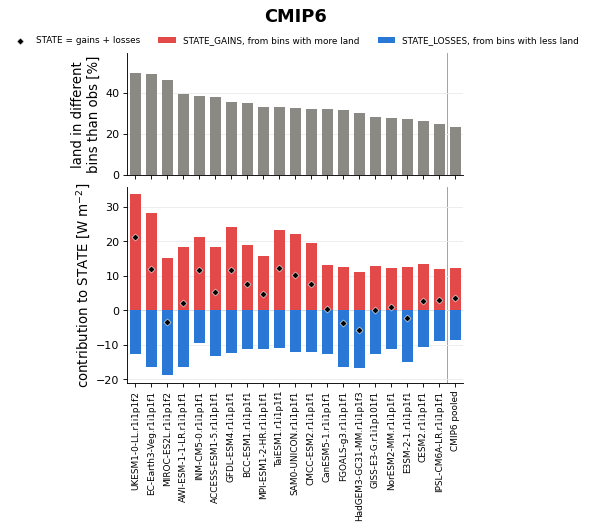

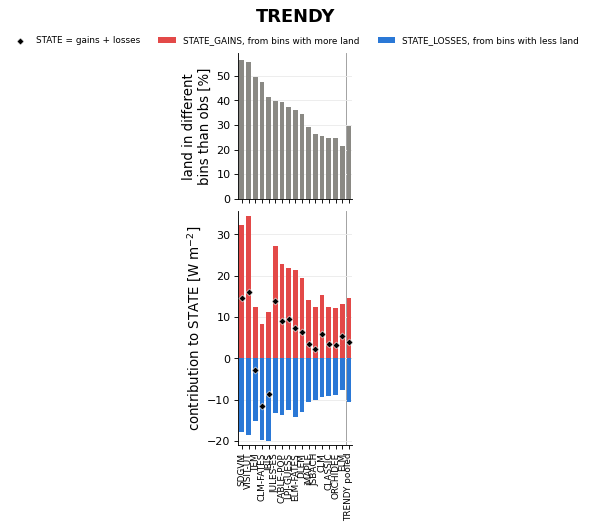

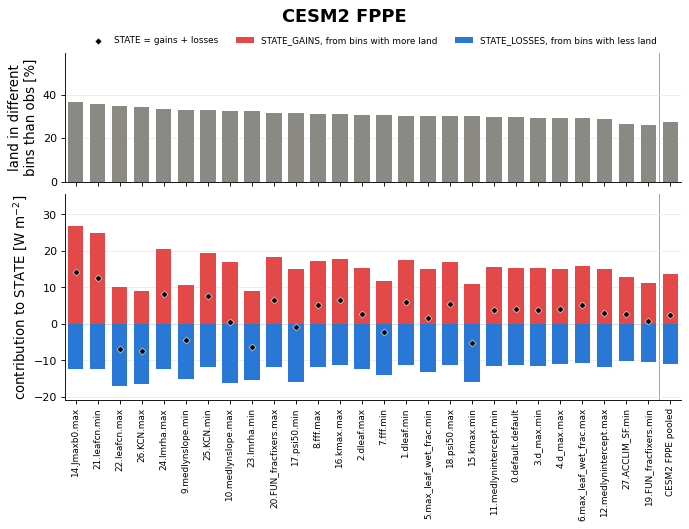

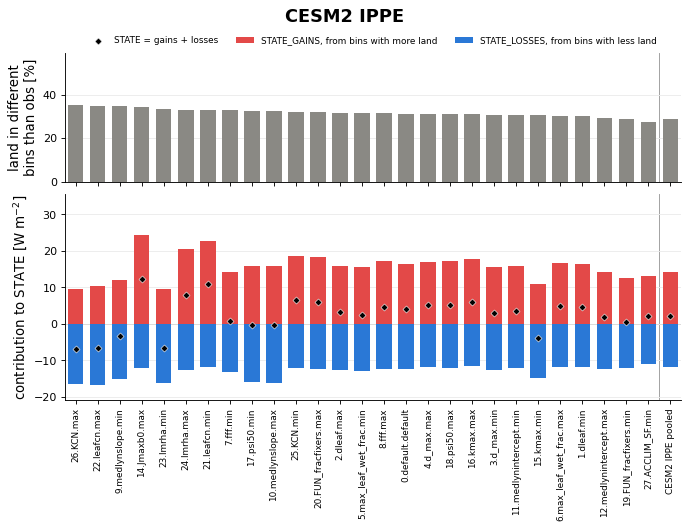

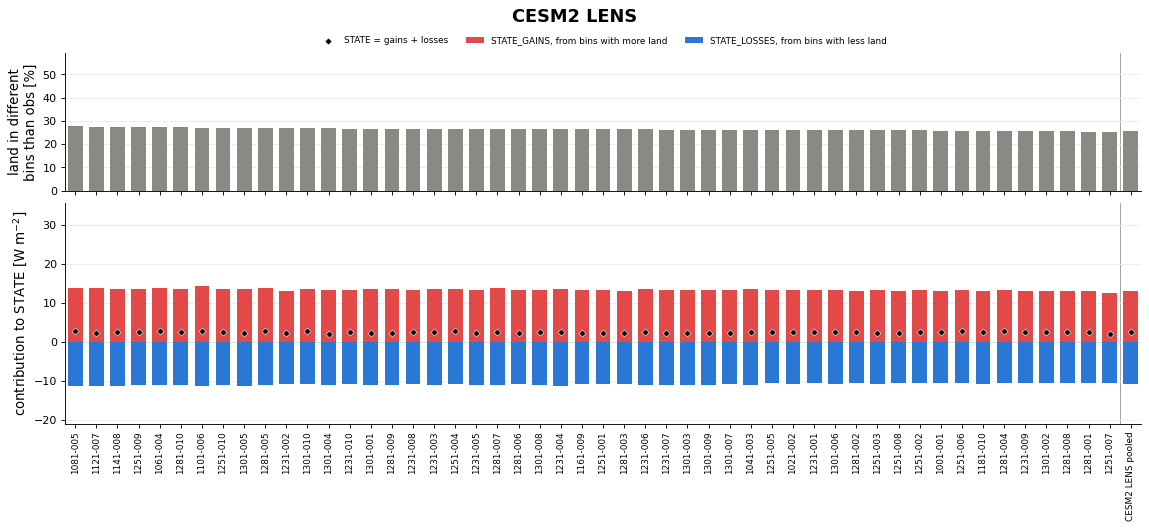

In [43]:
# Each dataset against obs_pooled: the land in other bins than obs_pooled, LAND_SHIFT = sum_b |p_m - p_r| / 2 (top),
# and STATE split into the bins the dataset gains land in and loses land from (bottom), members ordered by
# LAND_SHIFT (largest first), then the pooled family
SHIFT_COLORS = {"STATE_GAINS": "#e34948", "STATE_LOSSES": "#2a78d6", "LAND_SHIFT": "#8a8984"}

# Shared y-limits across families
shift_lim = (0, 105 * float(state_shift["LAND_SHIFT"].max()))
state_lim = (float(state_shift["STATE_LOSSES"].min()) - 1, float(state_shift["STATE_GAINS"].max()) + 1)

for f in FAMILIES:
    ds = state_shift.isel(dataset=np.flatnonzero((state_shift["family"] == f).values))
    is_member = ds["source"].values != "pooled"
    members_idx = np.flatnonzero(is_member)
    order = np.concatenate([members_idx[np.argsort(-ds["LAND_SHIFT"].values[is_member])], np.flatnonzero(~is_member)])
    ds = ds.isel(dataset=order)
    n = ds.sizes["dataset"]
    labels = [
        f"{FAMILY_KWARGS['labels'][f]} pooled" if s == "pooled"
        else e if f == "obs"
        else str(d).split(".", 1)[1]
        for d, s, e in zip(ds["dataset"].values, ds["source"].values, ds["et_product"].values)
    ]
    x = np.arange(n)

    fig, (ax0, ax1) = plt.subplots(
        nrows=2,
        sharex=True,
        figsize=(max(0.25 * n + 1.5, 4), 6.5),
        layout="constrained",
        dpi=DPI,
        gridspec_kw={"height_ratios": [1, 1.6]},
    )
    ax0.bar(x, 100 * ds["LAND_SHIFT"].values, width=0.7, color=SHIFT_COLORS["LAND_SHIFT"], zorder=2)
    ax0.set_ylim(shift_lim)
    ax0.set_ylabel("land in different\nbins than obs [%]", fontsize=12)

    ax1.bar(x, ds["STATE_GAINS"].values, width=0.7, color=SHIFT_COLORS["STATE_GAINS"], zorder=2,
            label="STATE_GAINS, from bins with more land")
    ax1.bar(x, ds["STATE_LOSSES"].values, width=0.7, color=SHIFT_COLORS["STATE_LOSSES"], zorder=2,
            label="STATE_LOSSES, from bins with less land")
    ax1.scatter(x, ds["STATE"].values, marker="D", s=20, color="k", edgecolor="w", linewidth=0.5, zorder=3,
                label="STATE = gains + losses")
    ax1.axhline(0, color="0.3", linewidth=0.8, zorder=1)
    ax1.set_ylim(state_lim)
    ax1.set_ylabel("contribution to STATE [W m$^{-2}$]", fontsize=12)

    # The pooled family set apart by a line
    if (~is_member).any():
        for ax in (ax0, ax1):
            ax.axvline(is_member.sum() - 0.5, color="0.6", linewidth=0.8, zorder=1)
    ax1.set_xticks(x, labels, fontsize=8, rotation=90)
    # At least 4 slots wide, centered on the datasets, so a family of 1-3 keeps narrow bars
    half = max(n, 4) / 2
    ax1.set_xlim((n - 1) / 2 - half, (n - 1) / 2 + half)
    for ax in (ax0, ax1):
        ax.grid(axis="y", color="0.92", zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
    # One legend row on wide figures, one column on narrow ones
    ax0.legend(*ax1.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncols=3 if n > 12 else 1, fontsize=8, frameon=False)
    fig.suptitle(FAMILY_KWARGS["labels"][f], fontsize=16, fontweight="bold")
    plt.show()